# Lost in Translation: Mandarin to Serbian that keeps who's talking

**AI + Languages track.** Serbian words change with the speaker's gender and with politeness, but Mandarin and English mostly don't show either. We translate Mandarin straight to Serbian, take the model's top 32 options, and use rules about Serbian word endings to pick the one that fits **who is speaking, who is listening and how formal it is**. When no option fits, it fixes the endings or warns "had to guess" instead of guessing silently.

**Who it helps:** a Mandarin speaker writing to Serbian colleagues at work who can't spot a wrong ending. Through English, a woman's "I already notified the driver" comes out as a man's sentence (*Obavestio sam vozača* instead of *Obavestila sam*), and a polite question to a manager can come out casual.

### Headline result: 45 test sentences the rules never saw

| System | chrF (0-100) | Gender right | Formality right | All tested endings right |
|---|---|---|---|---|
| Through English (baseline) | 42.5 | 9/21 (42.9%) | 14/22 (63.6%) | 19/40 (47.5%) |
| NLLB direct (its top answer) | 39.3 | 8/20 (40.0%) | 16/19 (84.2%) | 19/40 (47.5%) |
| **Ours: NLLB top 32 + picker** | **43.1** | **26/26 (100%)** | **21/21 (100%)** | **39/40 (97.5%)** |

Totals differ because rows where the ending doesn't show at all are left out. **Caveat:** gender and formality are graded by `detect()`, the same ending-reader our picker uses to choose, so our 100% is partly built in. chrF, which doesn't use it, shows the three systems about level. The fair test is the hand check below.

### The fair test: our Serbian speaker read all 135 answers

| System | Meaning right | Endings right | Meaning and endings both right |
|---|---|---|---|
| Through English (baseline) | **41/45 (91.1%)** | 19/40 (47.5%) | 20/45 (44.4%) |
| NLLB direct (its top answer) | 23/45 (51.1%) | 19/40 (47.5%) | 14/45 (31.1%) |
| **Ours: NLLB top 32 + picker** | 27/45 (60.0%) | **38/40 (95.0%)** | **26/45 (57.8%)** |

**In one line:** we fix the endings, but the route through English keeps the **meaning** far better (a gap the chance check says is real). Our meaning mistakes come from NLLB's options: the picker reads endings, not words. On "both right" we lead, but with 45 sentences we can't tell that lead apart from chance. Details in section 7.5.

### How to run

In Google Colab: **Runtime → Run all**. No sign-in, keys or uploads: the data loads from our public GitHub repo. A fresh Colab session first downloads the three models (about 3 GB, a few minutes); after that the whole notebook takes about 1.5 minutes on a plain CPU. A GPU (Runtime → Change runtime type → T4 GPU) is faster but optional. The same hardware gives the same numbers every run; the saved outputs come from a CPU run.

### Contents

1. [The problem and our approach](#problem)
2. [Setup](#setup)
3. [Data: our 60 labelled sentences](#data)
4. [Baseline: through English](#baseline)
5. [Our system: NLLB's 32 options + the picker](#our-system) (`detect()`, `repair()`, `pick()`)
6. [How we score](#scoring)
7. [**Results on the 45 test sentences**](#results) (the numbers above, the chance check, 5 real misses, our Serbian speaker's hand check)
8. [Demo: translate a new sentence](#demo)
9. [Supporting checks: the 15 practice rows](#practice)
10. [Limits and credits](#limits)

Colab's table of contents (the ☰ icon on the left) also jumps to any section.

### How it works

<img src="https://raw.githubusercontent.com/proelium27/veritas-ai-hackathon/main/docs/how-it-works.svg" width="420" alt="Flowchart: NLLB writes 32 Serbian options; for each option, find the helper word, read the endings and the 'you' words; keep the first option whose labels fit; if none fits, repair the endings; if that fails, warn 'had to guess'.">

<a name="problem" id="problem"></a>

## 1. The problem and our approach

**The problem.** In Serbian the words change with the speaker's gender ("I checked it" is *Proverio sam* from a man, *Proverila sam* from a woman) and with politeness (*ti si* to a friend, *Vi ste* to a boss). Mandarin marks politeness (您 is the polite "you", 你 the casual one) but usually not the speaker's gender. Tools that go through English lose both, because English has one "you" and no gendered verbs, so the Serbian tends to come out masculine.

**Three systems, the same sentences, the same scoring:**

1. **Baseline:** Mandarin → English → Serbian with two Helsinki-NLP models, the way many apps work.
2. **NLLB direct:** Meta's NLLB model translates Mandarin straight to Serbian; we take its top answer.
3. **Ours:** NLLB's top 32 answers plus our rules about Serbian endings, which pick the first answer that fits the speaker, listener and formality. If none fits, repair rules fix the endings; if that fails too, it warns "had to guess".

**Our own data and question.** Public translation benchmarks don't label who is speaking or listening, so we wrote 60 workplace sentences with those labels and a correct Serbian answer from our native Serbian speaker. We built the rules on 15 **practice** sentences and scored the 45 locked **test** sentences once, at the end.

<a name="setup" id="setup"></a>

## 2. Setup

Installs three small libraries, loads the rest, fixes the random seed and picks the hardware. Nothing here affects the results, so the install output is hidden.

- `sentencepiece` and `sacremoses` cut text into word pieces for the models; `sacrebleu` gives the chrF score. Colab already has pandas, PyTorch, transformers and matplotlib.
- The seed fixes anything random. Only the bootstrap check in section 7 uses randomness: the translations use *beam search*, which always gives the same output for the same input.
- `DEVICE` is an NVIDIA GPU (`cuda`) if there is one, else the CPU. We skip a Mac's GPU (`mps`): NLLB gave broken, repeating Serbian on it.

In [1]:
%%capture
# Install the three extras (%%capture hides pip's output). Takes a few seconds.
%pip install -q sentencepiece sacremoses sacrebleu

In [2]:
# Libraries, the fixed random seed, and the hardware the models run on.
import os, io, gc, time, random, urllib.request   # built into Python: files, timing, downloads
import warnings
warnings.filterwarnings("ignore")   # hide library warnings (e.g. Colab's "no HF_TOKEN" note); results don't change
import numpy as np                 # fast maths on lists of numbers
import pandas as pd                # tables (like a spreadsheet in Python)
import matplotlib.pyplot as plt    # charts
import torch                       # PyTorch: runs the neural translation models
import transformers                # Hugging Face: downloads and runs pre-trained models
import sacrebleu                   # the chrF translation score
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
transformers.logging.set_verbosity_error()   # only show real errors from Hugging Face, not notes

# Fix the random seed so every "Run all" gives the same results.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Use an NVIDIA GPU if there is one ("cuda", e.g. Colab's T4); otherwise the CPU.
# We don't use a Mac's own GPU ("mps"): in our test, NLLB gave broken, repeating Serbian on it
# and was slower than the CPU, while the CPU gave the right answers.
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Running on:", DEVICE, "(GPU)" if DEVICE == "cuda" else "(no GPU: slower, but it works)")

# Show whole sentences in tables instead of cutting them off with "...".
pd.set_option("display.max_colwidth", None)

print("pandas", pd.__version__, "| torch", torch.__version__,
      "| transformers", transformers.__version__, "| sacrebleu", sacrebleu.__version__)

Running on: cpu (no GPU: slower, but it works)
pandas 2.3.3 | torch 2.8.0 | transformers 4.57.6 | sacrebleu 2.6.0


<a name="data" id="data"></a>

## 3. Data: our 60 labelled sentences

Everyday workplace sentences that our team wrote and labelled (how we wrote them is in `data/README.md`). They load from the repo's public web address, so this works in a fresh Colab. What makes them useful: each row says **who is speaking, who is listening and whether it's formal**, and has a correct Serbian answer written by our native Serbian speaker without any translation tool.

| Column | What it holds |
|---|---|
| `id` | a unique number for the row |
| `mandarin` | the sentence in Mandarin (simplified characters) |
| `english_meaning` | what it means, in plain English (written by us, not by a model) |
| `speaker_gender` | who is talking: `man` or `woman` |
| `listener_gender` | who they're talking to: `man`, `woman` or `group` |
| `formal` | `yes` for the polite 您 (e.g. to a manager), `no` for the casual 你 |
| `what_it_tests` | which Serbian ending the row checks: `speaker_gender`, `listener_gender`, `formality`, or `control` (none); several are joined with `+` |
| `correct_serbian` | the correct Serbian in Latin letters (with č, ć, š, ž, đ, dž) |
| `notes` | anything worth knowing, e.g. other correct answers |
| `split` | `practice` (used to build the picker's rules) or `test` (locked until the rules were final) |

In [3]:
# Load our 60 sentences from the repo's public web address (every column read as text).
DATA_URL = "https://raw.githubusercontent.com/proelium27/veritas-ai-hackathon/main/data/test_sentences.csv"

# Backup places to look if the web address can't be reached (for example, no internet).
LOCAL_COPIES = [
    "data/test_sentences.csv",      # running from the repo's top folder
    "../data/test_sentences.csv",   # running from inside the notebook/ folder
    "test_sentences.csv",           # uploaded into Colab's Files panel
]

EXPECTED_COLUMNS = ["id", "mandarin", "english_meaning", "speaker_gender", "listener_gender",
                    "formal", "what_it_tests", "correct_serbian", "notes", "split"]


def read_table(source):
    """Read the CSV with every column as text, and empty cells as empty text ("")."""
    return pd.read_csv(source, dtype=str, keep_default_na=False)


def load_test_set():
    """Return (table, where it came from). Tries the web address first, then the local copies."""
    # 1) The public web address: this is what the judges will use.
    try:
        with urllib.request.urlopen(DATA_URL, timeout=30) as response:
            text = response.read().decode("utf-8")
        return read_table(io.StringIO(text)), DATA_URL
    except Exception as error:
        print(f"Couldn't download the test set from the web address ({error}).")

    # 2) A local copy, if the web address can't be reached.
    for path in LOCAL_COPIES:
        if os.path.exists(path):
            print(f"Using the local copy at {path} instead.")
            return read_table(path), path

    # 3) Nothing worked: say what to do in plain English, then stop.
    print("We couldn't find our test sentences. Two ways to fix it:\n"
          "  1. Check the internet connection, then run this cell again.\n"
          "  2. Or, in Colab, click the folder icon on the left, then Upload,\n"
          "     choose test_sentences.csv from the repo's data folder, and run this cell again.")
    raise FileNotFoundError("No test set found. See the message above.")


df, DATA_SOURCE = load_test_set()

# Check the columns are the ones we expect (a spreadsheet export can rename or drop them).
missing_columns = [c for c in EXPECTED_COLUMNS if c not in df.columns]
if missing_columns:
    raise ValueError(f"The test set is missing these columns: {missing_columns}. Compare it with data/README.md.")

# Remove stray spaces around every cell (spreadsheets sometimes add them).
df = df.apply(lambda column: column.str.strip())

print(f"Loaded {len(df)} sentences from: {DATA_SOURCE}")
if DATA_SOURCE != DATA_URL:
    print("Note: that's a local copy. Normally this cell loads it from the web address above.")
df.head()

Loaded 60 sentences from: https://raw.githubusercontent.com/proelium27/veritas-ai-hackathon/main/data/test_sentences.csv


,id,mandarin,english_meaning,speaker_gender,listener_gender,formal,what_it_tests,correct_serbian,notes,split
0,t01,我昨天加了两个小时的班。,I worked two extra hours yesterday.,woman,man,yes,speaker_gender,Juče sam radila dva sata prekovremeno.,No 'you' in sentence; listener and formality are just the scene.,practice
1,t02,我把报告写完了。,I finished writing the report.,man,woman,yes,speaker_gender,Završio sam pisanje izveštaja.,No 'you' in sentence; listener and formality are just the scene.,practice
2,t03,我已经到车间了。,I arrived to the workshop.,woman,woman,no,speaker_gender,Stigla sam u radionicu,"No 'you' in sentence; listener and formality are just the scene. Keep 'arrived' in the past tense in Serbian (not 'I am already at...'), so the ending shows.",practice
3,t04,我今天太累了。,I am too tired today.,man,man,no,speaker_gender,Danas sam previše umoran,No 'you' in sentence; listener and formality are just the scene. Speaker gender shows in the adjective 'tired'.,test
4,t05,我忘了带安全帽。,I forgot to wear my safety helmet.,woman,group,no,speaker_gender,Zaboravila sam da stavim zaštitnu kacigu.,No 'you' in sentence; listener and formality are just the scene.,test


### 3.1 Are the labels balanced?

If most speakers were men, a system that always writes the man's form would look good without being good. **Notice:** 30 women and 30 men speak, listeners are 27 men, 27 women and 6 groups, and formal and casual are close (27 and 33).

In [4]:
# Count the sentences by each label, to check the set isn't lopsided.
def tests_property(what_it_tests, prop):
    """True if a row's what_it_tests (e.g. "speaker_gender+formality") includes prop."""
    return prop in what_it_tests.split("+")

# One line per label: how many rows have each value.
for column in ["what_it_tests", "speaker_gender", "listener_gender", "formal", "split"]:
    counts = df[column].replace("", "(blank)").value_counts()
    print(f"{column:16s}", ", ".join(f"{value} {n}" for value, n in counts.items()))

# A row can test more than one thing, so also count rows per property.
print("\nRows that test each property (a row can test more than one):")
for prop in ["speaker_gender", "listener_gender", "formality", "control"]:
    n = df["what_it_tests"].apply(tests_property, prop=prop).sum()
    print(f"  {prop:16s} {n}")

# Rows without the correct Serbian can be translated, but not scored.
no_serbian = (df["correct_serbian"] == "").sum()
print(f"\nRows still missing correct_serbian: {no_serbian} of {len(df)}")

what_it_tests    speaker_gender 18, formality 12, listener_gender+formality 12, listener_gender 6, speaker_gender+formality 6, control 6
speaker_gender   woman 30, man 30
listener_gender  man 27, woman 27, group 6
formal           no 33, yes 27
split            test 45, practice 15

Rows that test each property (a row can test more than one):
  speaker_gender   24
  listener_gender  18
  formality        30
  control          6

Rows still missing correct_serbian: 0 of 60


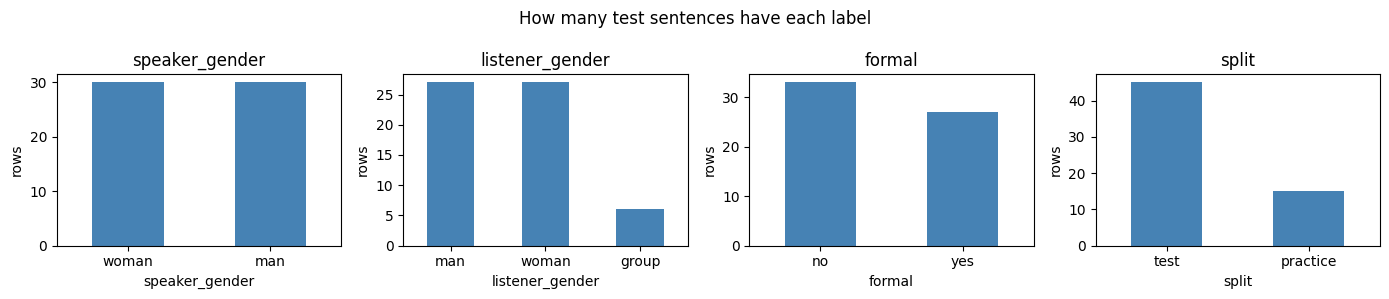

In [5]:
# The same counts as bar charts, one per label.
chart_columns = ["speaker_gender", "listener_gender", "formal", "split"]
fig, axes = plt.subplots(1, len(chart_columns), figsize=(14, 3))
for ax, column in zip(axes, chart_columns):
    df[column].replace("", "(blank)").value_counts().plot.bar(ax=ax, color="steelblue")
    ax.set_title(column)
    ax.set_ylabel("rows")
    ax.tick_params(axis="x", rotation=0)
fig.suptitle("How many test sentences have each label")
plt.tight_layout()
plt.show()

### 3.2 Practice rows and test rows

We use the `split` column exactly as our team set it while writing the sentences, and never moved a row after seeing results.

- **practice (15 rows):** we looked at these freely and wrote the picker's rules on them.
- **test (45 rows):** locked. The rules were frozen before we scored a single test row (section 7), and nothing changed afterwards. Until then, tables show practice rows only.

In [6]:
# Split into practice and test rows, and make `work`: the table every system writes its answers into.
USE_EXAMPLES = False  # True was a quick run on 4 example rows while building. It stays off.

# Rows with an empty split are the example rows.
df["split"] = df["split"].replace("", "example")

practice = df[df.split == "practice"]
test     = df[df.split == "test"]
examples = df[df.split == "example"]
print(f"practice rows: {len(practice)} | test rows: {len(test)} | example rows: {len(examples)}")

# Anything else in the split column is probably a typo: show it so someone fixes the CSV.
odd = df[~df.split.isin(["practice", "test", "example"])]
if len(odd):
    print("These rows have an unexpected split value and are left out:")
    display(odd[["id", "split"]])

# "work" is the set of rows we translate in sections 4 and 5.
if USE_EXAMPLES:
    work = examples.copy()
    print("USE_EXAMPLES is on: translating only the example rows, as a demo.")
else:
    work = pd.concat([practice, test]).copy()
    print("Translating all practice and test rows. Test results stay hidden until the rules are final.")

if len(work) == 0:
    raise ValueError("No rows to translate. If the example rows were deleted, set USE_EXAMPLES = False.")
work = work.reset_index(drop=True)

# Tables below only show rows that are not locked test rows.
def visible(table):
    return table[table.split != "test"]

practice rows: 15 | test rows: 45 | example rows: 0
Translating all practice and test rows. Test results stay hidden until the rules are final.


<a name="baseline" id="baseline"></a>

## 4. Baseline: through English

Many translation apps go through English, so this is the "what people use today" comparison. Two pre-trained models: `Helsinki-NLP/opus-mt-zh-en` (Mandarin → English), then `Helsinki-NLP/opus-mt-tc-base-en-sh` (English → Serbian; this model also covers Croatian and Bosnian, so each input starts with `>>srp_Cyrl<<` to ask for Serbian). We expect this route to lose the speaker's gender and the formal or casual "you", and we keep the English in the middle (`english_model`) so you can see where it disappears.

### 4.1 Helpers for every model

`load()` downloads a model and its *tokenizer* (which cuts text into the word pieces the model reads). `translate()` runs a model on a few sentences at a time with **beam search**: it keeps the best few guesses at each step and returns the best ones, most likely first. `free_memory()` hands memory back between steps.

In [7]:
# Helpers used for every model: load(), free_memory() and translate().
def load(name, **tokenizer_options):
    """Download a translation model and its tokenizer (only the first time), and put it on DEVICE."""
    start = time.time()
    tokenizer = AutoTokenizer.from_pretrained(name, **tokenizer_options)
    model = AutoModelForSeq2SeqLM.from_pretrained(name).to(DEVICE).eval()   # eval() = use it, not train it
    print(f"Loaded {name} in {time.time() - start:.0f} s")
    return tokenizer, model


def free_memory():
    """Give memory back after a step: Python's leftovers first, then the GPU's cache."""
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    elif DEVICE == "mps":
        torch.mps.empty_cache()


def translate(tokenizer, model, texts, n_options=1, batch_size=4, **generate_options):
    """Translate a list of sentences, a few at a time (batch_size), printing progress.
    Returns one list per sentence holding its n_options best translations, best first.
    Small batches keep memory low: 32 options for 16 sentences at once filled a 16 GB laptop."""
    results = []
    start = time.time()
    for first in range(0, len(texts), batch_size):
        chunk = texts[first:first + batch_size]
        batch = tokenizer(chunk, return_tensors="pt", padding=True).to(DEVICE)
        with torch.inference_mode():                               # no training, so skip the extra maths
            output = model.generate(**batch,
                                    num_beams=max(4, n_options),   # how many guesses beam search keeps
                                    num_return_sequences=n_options,
                                    max_new_tokens=128,            # plenty for one short sentence
                                    **generate_options)
        decoded = tokenizer.batch_decode(output, skip_special_tokens=True)
        # The model returns one flat list; regroup it into n_options per sentence.
        for i in range(len(chunk)):
            results.append(decoded[i * n_options:(i + 1) * n_options])
        del batch, output                                          # drop the big tensors before the next batch
        free_memory()
        if len(results) % 20 == 0 or len(results) == len(texts):   # a progress line every 20 sentences
            print(f"  {len(results)}/{len(texts)} done, {time.time() - start:.1f} s")
    return results

### 4.2 Serbian in Latin letters: `to_latin()`

Our correct answers are in Latin letters, but both models write Serbian in Cyrillic (NLLB has no "Serbian, Latin" setting). The two Serbian alphabets match letter for letter (ш is š, љ is lj), so converting is exact. Every model answer is converted as soon as it is made, and the cell checks the conversion on a few words.

In [8]:
# Serbian Cyrillic -> Latin, one letter at a time (small letters first).
CYRILLIC_TO_LATIN = {
    "а": "a", "б": "b", "в": "v", "г": "g", "д": "d", "ђ": "đ", "е": "e", "ж": "ž", "з": "z", "и": "i",
    "ј": "j", "к": "k", "л": "l", "љ": "lj", "м": "m", "н": "n", "њ": "nj", "о": "o", "п": "p", "р": "r",
    "с": "s", "т": "t", "ћ": "ć", "у": "u", "ф": "f", "х": "h", "ц": "c", "ч": "č", "џ": "dž", "ш": "š",
}
# Capital letters: Ш -> Š, and Љ -> "Lj" (not "LJ"), because a capital usually just starts a word.
CYRILLIC_TO_LATIN.update({cyr.upper(): lat.capitalize() for cyr, lat in list(CYRILLIC_TO_LATIN.items())})


def to_latin(text):
    """Write Serbian Cyrillic in Latin letters. Anything else (Latin, punctuation, spaces) stays as it is."""
    return "".join(CYRILLIC_TO_LATIN.get(letter, letter) for letter in text)


# Test it on a few words where we know the right answer.
checks = {"Проверила сам": "Proverila sam", "Љубав": "Ljubav", "Џеп": "Džep", "Ђак": "Đak",
          "Ћерка": "Ćerka", "Чаша, шешир, жут, цвет, јуче": "Čaša, šešir, žut, cvet, juče",
          "Њива": "Njiva", "Already Latin: šta": "Already Latin: šta"}
for cyrillic, expected in checks.items():
    result = to_latin(cyrillic)
    print("ok " if result == expected else "WRONG", f"{cyrillic} -> {result}")
    assert result == expected, f"to_latin({cyrillic!r}) gave {result!r}, expected {expected!r}"

ok  Проверила сам -> Proverila sam
ok  Љубав -> Ljubav
ok  Џеп -> Džep
ok  Ђак -> Đak
ok  Ћерка -> Ćerka
ok  Чаша, шешир, жут, цвет, јуче -> Čaša, šešir, žut, cvet, juče
ok  Њива -> Njiva
ok  Already Latin: šta -> Already Latin: šta


### 4.3 Translate every sentence through English

The first run downloads the two models (about 300 MB each). The table shows the practice rows. **Notice** t01 and t03: a woman is speaking, but the English "I" carries no gender and the Serbian comes out in the man's form (*Dodao sam*, *Bio sam*).

In [9]:
# Load the two baseline models (downloaded the first time only).
zh_en_tok, zh_en = load("Helsinki-NLP/opus-mt-zh-en")           # Mandarin -> English
en_sr_tok, en_sr = load("Helsinki-NLP/opus-mt-tc-base-en-sh")   # English -> Serbian/Croatian/Bosnian

Loaded Helsinki-NLP/opus-mt-zh-en in 1 s


Loaded Helsinki-NLP/opus-mt-tc-base-en-sh in 1 s


In [10]:
# Translate all 60 sentences Mandarin -> English -> Serbian; show the practice rows.
start = time.time()
mandarin = work["mandarin"].tolist()

# Step 1: Mandarin -> English (take the top answer for each sentence).
work["english_model"] = [options[0] for options in translate(zh_en_tok, zh_en, mandarin)]

# Step 2: English -> Serbian. ">>srp_Cyrl<<" asks for Serbian in Cyrillic.
english_inputs = [">>srp_Cyrl<< " + english for english in work["english_model"]]
work["baseline_cyrillic"] = [options[0] for options in translate(en_sr_tok, en_sr, english_inputs)]
work["baseline"] = work["baseline_cyrillic"].apply(to_latin)   # Latin, like our correct answers

print(f"Baseline: translated {len(work)} sentences in {time.time() - start:.1f} s")
visible(work)[["id", "mandarin", "english_meaning", "english_model", "baseline", "correct_serbian"]]

  20/60 done, 0.8 s


  40/60 done, 1.6 s


  60/60 done, 2.4 s


  20/60 done, 1.0 s


  40/60 done, 1.8 s


  60/60 done, 2.7 s
Baseline: translated 60 sentences in 5.0 s


,id,mandarin,english_meaning,english_model,baseline,correct_serbian
0,t01,我昨天加了两个小时的班。,I worked two extra hours yesterday.,I added two hours yesterday.,Dodao sam dva sata juče.,Juče sam radila dva sata prekovremeno.
1,t02,我把报告写完了。,I finished writing the report.,I've finished my report.,Završio sam izveštaj.,Završio sam pisanje izveštaja.
2,t03,我已经到车间了。,I arrived to the workshop.,I've been to the workshop.,Bio sam u radionici.,Stigla sam u radionicu
3,t06,我刚才看见叉车撞到货架了。,I just saw a forklift hit the shelves.,I just saw the forklift hit the shelf.,Upravo sam video viljuškar udario polici.,Upravo sam video kako je viljuškar udario u police
4,t22,你看到我的手套了吗？,Did you see my gloves?,Did you see my gloves?,Jesi li video moje rukavice?,Da li si video moje rukavice?
5,t23,你昨天几点走的？,When did you leave yesterday?,What time did you leave yesterday?,Kada ste juče otišli?,Kada si juče otišla?
6,t25,您需要帮忙吗？,Do you need help?,Can I help you?,Mogu li vam pomoći?,Da li vam treba pomoć?
7,t26,你需要帮忙吗？,Do you need help?,Do you need some help?,Treba li ti pomoć?,Da li ti treba pomoć?
8,t33,您要喝杯咖啡吗？,Do you need a cup of coffee?,Would you like a cup of coffee?,Želite li šolju kafe?,Hoćete li šolju kafe?
9,t39,我刚才给您打过电话。,I just called you.,I just called you.,Upravo sam te zvao.,Upravo sam Vas zvao.


<a name="our-system" id="our-system"></a>

## 5. Our system: NLLB's 32 options + the picker

NLLB (`facebook/nllb-200-distilled-600M`, Meta's "No Language Left Behind") translates Mandarin (`zho_Hans`) straight to Serbian (`srp_Cyrl`), with no English in the middle. We ask it for its **top 32** answers per sentence; its first answer is the **NLLB direct** system. Our picker then chooses among all 32:

1. `detect()` reads a Serbian sentence's endings: the speaker's gender, the listener's gender, formal or casual (5.2).
2. `fits()` says whether those match the row's labels (5.3).
3. `repair()` changes the endings when no option fits (5.4).
4. `pick()` puts it together (5.5): the first option that fits; else the first one `repair()` can fix; else NLLB's top answer, flagged "had to guess".

Why 32: in an earlier experiment (`notebook/more_options.ipynb`), a version with the right ending was among the options for 91% of sentences with 32 options, against 80% with 8.

### 5.1 NLLB's 32 options for every sentence

Frees the baseline models, loads NLLB (about 2.5 GB the first time) and translates. This is the slowest step: about a minute on a CPU. **Notice** that NLLB's top answer also defaults to the man's form for the women speakers in t01 and t03 (*dodao*, *Došao*).

In [11]:
# Free the baseline models, then load NLLB and tell it to write Serbian.
# The baseline models are done: free them before loading NLLB, so a laptop doesn't run out of memory.
# (The demo in section 8 loads them again; they are already downloaded, so that's quick.)
del zh_en, en_sr
free_memory()

# src_lang tells the tokenizer the input is Mandarin in simplified characters.
nllb_tok, nllb = load("facebook/nllb-200-distilled-600M", src_lang="zho_Hans")

# NLLB must be told the output language: we force the first word to be the "Serbian, Cyrillic" tag.
SERBIAN = nllb_tok.convert_tokens_to_ids("srp_Cyrl")

Loaded facebook/nllb-200-distilled-600M in 2 s


In [12]:
# NLLB: 32 Serbian options for every sentence; the first one is the "NLLB direct" answer.
N_OPTIONS = 32

start = time.time()
# One sentence at a time (batch_size=1): 32 options per sentence already makes a big batch.
work["options_cyrillic"] = translate(nllb_tok, nllb, work["mandarin"].tolist(), n_options=N_OPTIONS,
                                     batch_size=1, forced_bos_token_id=SERBIAN)
# Convert every option to Latin letters (see to_latin in section 4).
work["options"] = [[to_latin(option) for option in options] for options in work["options_cyrillic"]]
work["direct_cyrillic"] = [options[0] for options in work["options_cyrillic"]]
work["direct"] = [options[0] for options in work["options"]]   # NLLB's single best answer, in Latin
print(f"NLLB: {N_OPTIONS} options for each of {len(work)} sentences in {time.time() - start:.1f} s")

visible(work)[["id", "mandarin", "direct", "correct_serbian"]]

  20/60 done, 18.1 s


  40/60 done, 46.2 s


  60/60 done, 63.4 s
NLLB: 32 options for each of 60 sentences in 63.4 s


,id,mandarin,direct,correct_serbian
0,t01,我昨天加了两个小时的班。,Ja sam dodao dva sata u rad juče.,Juče sam radila dva sata prekovremeno.
1,t02,我把报告写完了。,Spisao sam izveštaj.,Završio sam pisanje izveštaja.
2,t03,我已经到车间了。,Došao sam u radionicu.,Stigla sam u radionicu
3,t06,我刚才看见叉车撞到货架了。,To što sam video je da se vinka udari u policu.,Upravo sam video kako je viljuškar udario u police
4,t22,你看到我的手套了吗？,Vidiš li moje rakavice?,Da li si video moje rukavice?
5,t23,你昨天几点走的？,Koliko si otišao juče?,Kada si juče otišla?
6,t25,您需要帮忙吗？,Da li vam je potrebna pomoć?,Da li vam treba pomoć?
7,t26,你需要帮忙吗？,Da li vam je potrebna pomoć?,Da li ti treba pomoć?
8,t33,您要喝杯咖啡吗？,Da li želite kafu?,Hoćete li šolju kafe?
9,t39,我刚才给您打过电话。,Samo sam vam se javio.,Upravo sam Vas zvao.


*Plumbing:* the next cell saves the 32 options to the `outputs` folder (practice and test rows in separate files), so our Serbian speaker could read them without running the model.

In [13]:
# Save the 32 options to outputs/ (practice and locked test rows in separate files).
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Spread the list of options into one column per option.
options_table = work[["id", "split", "mandarin", "speaker_gender", "listener_gender", "formal"]].copy()
for k in range(N_OPTIONS):
    options_table[f"option_{k + 1}"] = [options[k] for options in work["options"]]

files = {
    "nllb_options.csv": options_table[options_table.split != "test"],
    "nllb_options_TEST_LOCKED.csv": options_table[options_table.split == "test"],
}
for filename, table in files.items():
    if len(table):
        path = os.path.join(OUTPUT_DIR, filename)
        table.to_csv(path, index=False, encoding="utf-8")
        print(f"Saved {len(table)} rows to {path}")

Saved 15 rows to outputs/nllb_options.csv
Saved 45 rows to outputs/nllb_options_TEST_LOCKED.csv


### 5.2 Reading the endings: `detect()`

The heart of the picker. `detect()` reads one Serbian sentence and returns the **speaker's gender**, the **listener's gender** and whether the "you" is **formal**: `"man"` / `"woman"`, `"yes"` / `"no"`, `None` (the sentence doesn't show it) or `"mixed"` (it shows both, always counted wrong). Our native Serbian speaker checked every rule on the practice rows and answered 10 follow-up questions (*Answer Q1* to *Q10* in the comments).

- **Speaker:** Serbian says "I did" with the helper *sam* next to a past form: ending **-la** means a woman (*proverila*), **-o** a man (*proverio*, *došao*), plus a word list for describing words (*umoran* / *umorna*). We look at the word before *sam* and up to 3 after, stopping at punctuation or words like *da, što, koji* (in *Rekao sam da je ona došla* the speaker is a man). Look-alikes are ignored (*posao* "job", *kao* "like", *posla*, *škola*), and *sam* meaning "alone" is told apart from the helper.
- **Listener:** the same idea with the casual *si* / *jesi* / *nisi* (*Da li si došla?* is asked to a woman). Formal *Vi* takes the plural for anyone, so the listener's gender is never checked on formal rows.
- **Formality:** formal signs are *Vi, Vas, Vam, Vaš…, ste, biste*, verbs in **-te** (*možete*) and formal commands (*Potpišite*); casual signs are *ti, tebe, tvoj…, si*, verbs in **-š** (*možeš*) and casual commands (*Potpiši*). A first word ending in -ti or -ći is an infinitive, not a command (*Doći ću sutra*).
- **The word *te*** means casual "you" but also "those", so it only counts in *molim te* and on one hand-marked practice row (t39).

In [14]:
# detect(): read a Serbian sentence's endings. Every word list comes from our Serbian speaker's checked rules.
import re

# ---- Word lists, all taken from our Serbian speaker's checked rules ----
# A comment like "# Answer Q4" points to our Serbian speaker's answer to our 4th follow-up question
# (listed in docs/log.md, Sat Nov 14).

# Helper words. "sam" / "nisam" = "I am" / "I am not": the word next to them shows the SPEAKER's gender.
# "si" / "jesi" / "nisi" = casual "you are": the word next to them shows the LISTENER's gender.
SPEAKER_HELPERS = {"sam", "nisam"}
LISTENER_HELPERS = {"si", "jesi", "nisi"}
# Answer Q1: "sama", "samo", "sami", "same" are never the helper, so they are not in the list above.
# Other forms of "to be" (is, you are, we are, you all are, they are). If the clause already has one,
# a "sam" in it means "alone", not "I am": "Ostao je sam" = "He stayed alone".
OTHER_BE_WORDS = {"je", "si", "smo", "ste", "su"}

# After these words the next verb can belong to someone else ("Rekao sam da je ona došla"), so we stop looking.
STOP_WORDS = {"da", "što", "koji", "koja", "kad", "ali"}
LOOK_AHEAD = 3   # how many words after the helper we look at

# Words that end like a man's past form (-ao, -eo, -io, -uo) but are not verbs.
NOT_VERBS = {"kao", "posao", "deo", "ceo", "pepeo", "orao", "žao", "zao", "sto"}
# Answer Q9: nouns that end in -la like a woman's past form ("Posle posla sam otišao" is a man).
NOT_LA_VERBS = {"posla", "stola", "pola", "škola", "kola"}

# Describing words (adjectives): the man's form and the woman's form.
ADJECTIVES = {"spreman": "spremna", "umoran": "umorna", "siguran": "sigurna", "gladan": "gladna",
              "srećan": "srećna", "zadovoljan": "zadovoljna", "bolestan": "bolesna", "svestan": "svesna",
              "radostan": "radosna", "gotov": "gotova", "povređen": "povređena", "zauzet": "zauzeta",
              "kriv": "kriva", "zaposlen": "zaposlena", "ljut": "ljuta"}
MAN_ONLY_WORDS = {"umro"}      # Answer Q3: the man's form of umrla ("died") doesn't end in -ao/-eo/-io/-uo
WOMAN_ONLY_WORDS = {"sama"}   # "Sama sam kod kuće" = a woman. (A "sam" that means "alone" is handled below.)

# Formal "you": Vi / Vas / Vam, every form of Vaš, ste / jeste / niste / biste, nemojte.
FORMAL_WORDS = {"vi", "vas", "vam", "vama", "vaš", "vaša", "vaše", "vašeg", "vašem", "vašu", "vašim",
                "vašoj", "vaših", "vašima", "ste", "jeste", "niste", "biste", "nemojte"}
# Casual "you": ti / tebe / tebi / tobom, every form of tvoj, si / jesi / nisi, nemoj.
# ("te" is left out: it also means "those" and "and so". Only "molim te" counts, plus the rows below.)
INFORMAL_WORDS = {"ti", "tebe", "tebi", "tobom", "tvoj", "tvoja", "tvoje", "tvog", "tvom", "tvoju",
                  "tvojim", "tvojoj", "tvojih", "tvome", "si", "jesi", "nisi", "nemoj"}
NOT_TE_VERBS = {"dete", "plate", "karte", "minute", "kante"}   # nouns that end in -te
NOT_Š_VERBS = {"još", "baš", "naš", "loš", "keš", "vaš"}        # words that end in -š but aren't casual verbs
NOT_COMMANDS = {"taj", "moj", "kraj", "li", "mi"}               # end in -i / -j but aren't commands

# Answer Q6: a rule for "te" would miss "Vidim te" and "Pitao sam te", so we mark by hand the rows
# whose "te" means casual "you". Built from the PRACTICE rows only: t39 ("I just called you"), where
# the casual way to say it is "Pozvao sam te". Test rows are never marked, so on them "te" counts
# only in "molim te".
TE_MEANS_YOU = {"t39"}


def split_words(sentence):
    """Cut a sentence into [gap, word, gap, word, ..., gap]. Words are at the odd positions;
    a gap is the spaces and punctuation between two words. Joining the pieces gives the sentence back."""
    return re.split(r"(\w+)", sentence)


def words_and_breaks(sentence):
    """The words in lowercase, and for each word whether punctuation comes right after it."""
    pieces = split_words(sentence)
    words = [w.lower() for w in pieces[1::2]]
    breaks = [pieces[2 * k + 2].strip() != "" for k in range(len(words))]
    return words, breaks


def clause_span(words, breaks, i):
    """Where the part of the sentence holding word i starts and ends (both positions included).
    We cut at punctuation and before a stop word."""
    start = i
    while start > 0 and not breaks[start - 1] and words[start] not in STOP_WORDS:
        start -= 1
    end = i
    while end + 1 < len(words) and not breaks[end] and words[end + 1] not in STOP_WORDS:
        end += 1
    return start, end


def clause(words, breaks, i):
    """The words in the same part of the sentence as word i."""
    start, end = clause_span(words, breaks, i)
    return words[start:end + 1]


def helper_spots(words, breaks, helpers):
    """Positions of the words that really are helpers.
    Answer Q1: the helper "sam" never starts a sentence, so a first-word "Sam" means "alone"; and if its
    clause already has je/si/smo/ste/su ("Ostao je sam"), that "sam" means "alone" too.
    We only look for je/si/... BEFORE "sam": in "Video sam kako je pao" the "je" comes later and
    belongs to the next part ("how it fell"), so that "sam" is still the helper."""
    spots = []
    for i, word in enumerate(words):
        if word not in helpers:
            continue
        start, _ = clause_span(words, breaks, i)
        if word == "sam" and (i == 0 or OTHER_BE_WORDS & set(words[start:i])):
            continue                                       # "sam" = alone, not "I am"
        spots.append(i)
    return spots


def near_helpers(words, breaks, helpers):
    """Positions of the words next to a helper word: the word right before it, and up to
    LOOK_AHEAD words after it, stopping at punctuation or a stop word."""
    positions = []
    for i in helper_spots(words, breaks, helpers):
        if i > 0 and not breaks[i - 1]:
            positions.append(i - 1)
        for j in range(i + 1, min(i + 1 + LOOK_AHEAD, len(words))):
            if breaks[j - 1] or words[j] in STOP_WORDS:
                break
            positions.append(j)
    return positions


def word_gender(word):
    """'man', 'woman' or None for one lowercase word: a past form (-o / -la) or a describing word."""
    if word in ADJECTIVES or word in MAN_ONLY_WORDS:
        return "man"
    if word in ADJECTIVES.values() or word in WOMAN_ONLY_WORDS:
        return "woman"
    if word in NOT_VERBS or word in NOT_LA_VERBS:
        return None
    if word.endswith(("ao", "eo", "io", "uo")):
        return "man"
    if word.endswith("la") and len(word) >= 4:
        return "woman"
    return None


def is_alone_sam(words, breaks, k):
    """True if word k is a "sam" that means "alone" (a man's word), not the helper (Answer Q1)."""
    return words[k] == "sam" and k not in helper_spots(words, breaks, SPEAKER_HELPERS)


def gender_near(words, breaks, helpers):
    """The gender shown by the words next to the helpers: 'man', 'woman',
    'mixed' (both show up, which is always wrong) or None (no sign).
    Answer Q9: a sentence that shows both genders is flagged as 'mixed'."""
    found = set()
    for k in near_helpers(words, breaks, helpers):
        found.add("man" if is_alone_sam(words, breaks, k) else word_gender(words[k]))
    found -= {None}
    if len(found) == 2:
        return "mixed"
    return found.pop() if found else None


def command_word(words):
    """The word that would be a command: the first word, or the word after "molim te" / "molim Vas"."""
    for i in range(len(words) - 2):
        if words[i] == "molim" and words[i + 1] in ("te", "vas"):
            return words[i + 2]
    return words[0] if words else ""


def formality(words, te_means_you=False):
    """'yes' (formal Vi), 'no' (casual ti), 'mixed' (both, always wrong) or None (no sign)."""
    formal = informal = False
    for word in words:
        if word in FORMAL_WORDS or (len(word) >= 5 and word.endswith("te") and word not in NOT_TE_VERBS):
            formal = True
        if word in INFORMAL_WORDS or (word.endswith("š") and word not in NOT_Š_VERBS):
            informal = True
    if any(a == "molim" and b == "te" for a, b in zip(words, words[1:])):
        informal = True                                   # "molim te" = casual "please"
    if te_means_you and "te" in words:
        informal = True                                   # Answer Q6: a hand-marked row, "te" = casual "you"
    command = command_word(words)
    if command in FORMAL_WORDS or command in INFORMAL_WORDS:
        pass                                              # a "you" word, already counted above
    elif command.endswith(("ite", "ajte", "jte")):
        formal = True                                     # Potpišite, Čekajte: formal command
    elif command.endswith(("ti", "ći")):
        pass                                              # Answer Q2: doći, reći, raditi are infinitives, never
                                                          # commands (risk: a missing mark, reci vs reći)
    elif command.endswith(("i", "j")) and command not in NOT_COMMANDS:
        informal = True                                   # Potpiši, Čekaj: casual command
    if formal and informal:
        return "mixed"
    return "yes" if formal else "no" if informal else None


def detect(serbian, te_means_you=False):
    """Read one Serbian sentence (Latin letters) and say what it shows.
    Returns speaker ('man'/'woman'), listener ('man'/'woman') and formal ('yes'/'no');
    None means the sentence doesn't show it, 'mixed' means it shows both (always counted wrong).
    te_means_you=True for the hand-marked rows where "te" means casual "you" (Answer Q6)."""
    words, breaks = words_and_breaks(serbian)
    return dict(speaker=gender_near(words, breaks, SPEAKER_HELPERS),
                listener=gender_near(words, breaks, LISTENER_HELPERS),
                formal=formality(words, te_means_you))


def detect_row(serbian, row):
    """detect() for one row of our table: also passes whether this row's "te" means "you"."""
    return detect(serbian, te_means_you=row.get("id") in TE_MEANS_YOU)

**Check: `detect()` hand tests.** Short sentences with a known answer, mostly from our Serbian speaker's rule sheet. The cell prints only failures (and stops if there are any), then three known limits we didn't fix.

In [15]:
# Hand tests: sentences from our Serbian speaker's rule sheet, with the answer we expect.
# Each line: sentence, then the expected (speaker, listener, formal). None = doesn't show.
DETECT_TESTS = [
    ("Proverila sam.",                       ("woman", None, None)),
    ("Nisam čula.",                          ("woman", None, None)),
    ("Proverio sam.",                        ("man", None, None)),
    ("Već sam ga isključila.",               ("woman", None, None)),
    ("Ja sam joj to rekla.",                 ("woman", None, None)),
    ("Već sam Vam to poslala.",              ("woman", None, "yes")),
    ("Juče sam se razbolela.",               ("woman", None, None)),
    ("Rekao sam da je ona došla.",           ("man", None, None)),   # došla is after "da": someone else
    ("Završila sam posao.",                  ("woman", None, None)), # posao is a noun, not a man's verb
    ("Veseo sam.",                           ("man", None, None)),
    ("Umorna sam.",                          ("woman", None, None)), # describing word before sam
    ("Danas sam umoran.",                    ("man", None, None)),
    ("Sama sam kod kuće.",                   ("woman", None, None)),
    ("Posao je gotov.",                      (None, None, None)),    # gotov describes the job, no sam
    ("Treba mi pomoć.",                      (None, None, None)),
    ("Kada si juče otišla?",                 (None, "woman", "no")),
    ("Da li si došao?",                      (None, "man", "no")),
    ("Jesi li povređena?",                   (None, "woman", "no")),
    ("Jesi li umoran?",                      (None, "man", "no")),
    ("Zar nisi došla?",                      (None, "woman", "no")),
    ("Vidiš li moje rukavice?",              (None, None, "no")),    # present tense: no gender
    ("Jeste li došli?",                      (None, None, "yes")),   # formal plural: no gender
    ("Da li Vam treba pomoć?",               (None, None, "yes")),
    ("Vaš paket je na portirnici.",          (None, None, "yes")),
    ("Možete li sutra da dođete ranije?",    (None, None, "yes")),
    ("Možeš li sutra da dođeš ranije?",      (None, None, "no")),
    ("Tvoja kartica je ovde.",               (None, None, "no")),
    ("Imam još karte.",                      (None, None, None)),    # još and karte are not "you" words
    ("Potpišite se ovde.",                   (None, None, "yes")),
    ("Potpiši se ovde.",                     (None, None, "no")),
    ("Molim Vas, sačekajte.",                (None, None, "yes")),
    ("Molim te, sačekaj.",                   (None, None, "no")),
    ("Taj čovek je ovde.",                   (None, None, None)),    # taj is not a command
    ("Nemojte to.",                          (None, None, "yes")),
    ("Nemoj to.",                            (None, None, "no")),
    ("Da li ti treba pomoć, molim Vas?",     (None, None, "mixed")), # both kinds of "you": always wrong
    # Answer Q1: "sam" can also mean "alone".
    ("Ostao je sam.",                        (None, None, None)),    # "je" is there, so sam = alone
    ("Jutros je sam došao.",                 (None, None, None)),    # he came alone: not the speaker
    ("Sam sam završio posao.",               ("man", None, None)),   # first "Sam" = alone, second = helper
    ("Video sam kako je pao.",               ("man", None, None)),   # "je" comes after sam: sam is the helper
    # Answer Q2: infinitives end in -ti or -ći and are never commands.
    ("Doći ću sutra.",                       (None, None, None)),    # "I will come": not a casual command
    ("Reći ću mu.",                          (None, None, None)),
    ("Raditi ovde je lepo.",                 (None, None, None)),
    ("Dođi sutra.",                          (None, None, "no")),    # a real casual command
    ("Reci mu.",                             (None, None, "no")),
    # Answer Q9: nouns ending in -la are not a woman's verb; both genders together = "mixed".
    ("Posle posla sam otišao.",              ("man", None, None)),
    ("Pola sam završio.",                    ("man", None, None)),
    ("Došla sam i rekao sam.",               ("mixed", None, None)),
]

# Answer Q6: on a hand-marked row, "te" means casual "you" (our Serbian speaker's examples, read as a marked row).
TE_TESTS = [
    ("Vidim te.",                            (None, None, "no")),
    ("Pitao sam te.",                        ("man", None, "no")),
]

failures = 0
for sentence, expected, te_means_you in ([(s, e, False) for s, e in DETECT_TESTS] +
                                         [(s, e, True) for s, e in TE_TESTS]):
    found = detect(sentence, te_means_you)
    got = (found["speaker"], found["listener"], found["formal"])
    ok = got == expected
    failures += not ok
    marked = " (te = you)" if te_means_you else ""
    if not ok:                                                   # print only the tests that fail
        print("WRONG", f"{sentence + marked:38s} -> {got}   expected {expected}")
total = len(DETECT_TESTS) + len(TE_TESTS)
print(f"{total - failures} of {total} hand tests pass.")
assert failures == 0, "A hand test failed: fix detect() before going on."

# Known limits: sentences we know detect() reads wrongly, shown so nobody is surprised.
KNOWN_LIMITS = [
    ("Vrati to.", "a casual command ending in -ti (vratiti -> vrati) looks like an infinitive (Answer Q2): to check"),
    ("Reci mi sutra.", "fine, but typed without the mark, 'Reci' (say!) and 'Reći' (to say) look the same"),
    ("Vidim te.", "on a row that isn't hand-marked, 'te' doesn't count as 'you' (Answer Q6)"),
]
print("\nKnown limits (not fixed):")
for sentence, why in KNOWN_LIMITS:
    print(f"  {sentence:16s} -> {detect(sentence)}   ({why})")

50 of 50 hand tests pass.

Known limits (not fixed):
  Vrati to.        -> {'speaker': None, 'listener': None, 'formal': None}   (a casual command ending in -ti (vratiti -> vrati) looks like an infinitive (Answer Q2): to check)
  Reci mi sutra.   -> {'speaker': None, 'listener': None, 'formal': 'no'}   (fine, but typed without the mark, 'Reci' (say!) and 'Reći' (to say) look the same)
  Vidim te.        -> {'speaker': None, 'listener': None, 'formal': None}   (on a row that isn't hand-marked, 'te' doesn't count as 'you' (Answer Q6))


### 5.3 Does an option fit? `tested()` and `fits()`

`tested(row)` lists what a row checks (from its `what_it_tests` label). `fits(serbian, row)` is True when `detect()` finds the right value for every one of those.

In [16]:
# Which detect() answer goes with which label column, for each property in what_it_tests.
PROPERTY_CHECKS = {
    "speaker_gender":  ("speaker",  "speaker_gender"),
    "listener_gender": ("listener", "listener_gender"),
    "formality":       ("formal",   "formal"),
}


def tested(row):
    """The properties this row checks, from its what_it_tests column. Formal Vi uses the plural
    for a man or a woman, so on formal rows the listener's gender can't show and isn't checked."""
    needed = [p for p in PROPERTY_CHECKS if tests_property(row["what_it_tests"], p)]
    if row["formal"] == "yes" and "listener_gender" in needed:
        needed.remove("listener_gender")
    return needed


def fits(serbian, row):
    """True if every property this row tests shows up in the Serbian with the right value."""
    found = detect_row(serbian, row)   # detect_row() is detect() plus the hand-marked "te" rows
    return all(found[PROPERTY_CHECKS[p][0]] == row[PROPERTY_CHECKS[p][1]] for p in tested(row))

### 5.4 Fixing the endings: `repair()`

When none of the 32 options fits, we try to change the endings of one, using our Serbian speaker's repair table. Only the words next to the helper words change, and the result must pass `fits()` or we don't use it. Repair changes endings, never words.

- **Man → woman:** *-io → -ila*, *-eo → -ela*, *-ao → -ala*, *-uo → -ula* (*proverio → proverila*); irregular verbs from a fixed list drop the *a* (*došao → došla*, *rekao → rekla*); describing words from the word list.
- **Woman → man:** drop *-la*, then add *-o* after a vowel or *-ao* after a consonant (*proverila → proverio*, *došla → došao*), with two exceptions (*umrla → umro*, *rasla → rastao*).
- **Casual → formal:** *si → ste*, and the verb next to it goes plural (*došao → došli*); *možeš → možete*; *ti → Vi* or *Vam*; *tvoj → Vaš*; commands get *-te*; *molim te → molim Vas*.
- **Formal → casual:** the reverse, using the listener's gender from the row (*došli ste → došla si*). *Vas* becomes *tebe* or *te* and *Vama* becomes *tobom* or *tebi*, depending on the word before; a sentence ending in "?" stays a question.

In [17]:
# repair(): change an option's endings to fit the row's labels (our Serbian speaker's repair table).
# ---- The repair table, from our Serbian speaker's checked list ----

# Irregular past forms: the "a" drops for a woman (došao -> došla). Spelling can't tell these apart
# from regular ones (rekao -> rekla, but čekao -> čekala), so they must be a fixed list.
IRREGULAR_PAST = {"došao": "došla", "pošao": "pošla", "otišao": "otišla", "ušao": "ušla",
                  "izašao": "izašla", "našao": "našla", "pronašao": "pronašla", "prošao": "prošla",
                  "sišao": "sišla", "išao": "išla", "rekao": "rekla", "pekao": "pekla", "tekao": "tekla",
                  "vukao": "vukla", "sekao": "sekla", "mogao": "mogla", "pomogao": "pomogla",
                  "stigao": "stigla", "legao": "legla"}
# Every other past form follows the regular endings: -io -> -ila, -eo -> -ela, -ao -> -ala, -uo -> -ula.
REGULAR_ENDINGS = {"io": "ila", "eo": "ela", "ao": "ala", "uo": "ula"}

# Answer Q3: woman -> man does NOT simply reverse the table. For verbs: drop -la, then add -o after a
# vowel (proverila -> proverio) or -ao after a consonant (došla -> došao). Two exceptions:
MAN_EXCEPTIONS = {"umrla": "umro", "rasla": "rastao"}
# Describing words need the word list (umorna -> umoran, but gotova -> gotov).
WOMAN_TO_MAN_ADJECTIVES = {woman: man for man, woman in ADJECTIVES.items()}
VOWELS = set("aeiou")

# Casual "your" -> formal "your".
TVOJ_TO_VAS = {"tvoj": "Vaš", "tvoja": "Vaša", "tvoje": "Vaše", "tvog": "Vašeg", "tvom": "Vašem",
               "tvoju": "Vašu", "tvojim": "Vašim", "tvojoj": "Vašoj", "tvojih": "Vaših"}
# Other casual words with exactly one formal partner.
CASUAL_TO_FORMAL = {"si": "ste", "jesi": "jeste", "nisi": "niste", "nemoj": "nemojte",
                    "tebe": "Vas", "tebi": "Vama", "tobom": "Vama", **TVOJ_TO_VAS}
# Formal -> casual, only where there is exactly one casual partner.
# Answer Q4: Vam -> ti always. Answer Q3: biste -> bi. (Vas and Vama depend on the word before: see below.)
FORMAL_TO_CASUAL = {"ste": "si", "jeste": "jesi", "niste": "nisi", "nemojte": "nemoj", "biste": "bi",
                    "vi": "ti", "vam": "ti", **{v.lower(): k for k, v in TVOJ_TO_VAS.items()}}
# Answer Q4: Vas -> tebe after a preposition (za Vas -> za tebe) or at the start, otherwise te.
PREPOSITIONS = {"za", "na", "u", "o", "po", "pri", "od", "do", "iz", "kod", "bez", "oko", "pre", "posle",
                "prema", "kroz", "pored", "zbog", "umesto", "osim", "protiv", "ka", "k",
                "s", "sa", "pred", "nad", "pod", "među"}
# Answer Q4: Vama -> tobom after these ("with / in front of / above / under / among you"), otherwise tebi.
TOBOM_PREPOSITIONS = {"s", "sa", "pred", "nad", "pod", "među"}


def to_woman(word):
    """A man's past form or describing word -> the woman's form (lowercase in, lowercase out)."""
    if word in ADJECTIVES:
        return ADJECTIVES[word]
    if word in IRREGULAR_PAST:
        return IRREGULAR_PAST[word]
    for man_end, woman_end in REGULAR_ENDINGS.items():
        if word.endswith(man_end) and word not in NOT_VERBS:
            return word[:-len(man_end)] + woman_end
    return word


def to_man(word):
    """A woman's past form or describing word -> the man's form (Answer Q3).
    Anything we aren't sure about is left as it is."""
    if word in WOMAN_TO_MAN_ADJECTIVES:
        return WOMAN_TO_MAN_ADJECTIVES[word]              # umorna -> umoran, gotova -> gotov
    if word == "sama":
        return "sam"                                      # Answer Q1: "alone", said by a man
    if word in MAN_EXCEPTIONS:
        return MAN_EXCEPTIONS[word]                       # umrla -> umro, rasla -> rastao
    if word.endswith("la") and len(word) >= 4 and word not in NOT_LA_VERBS:
        stem = word[:-2]                                  # proverila -> proveri, došla -> doš
        return stem + "o" if stem[-1] in VOWELS else stem + "ao"
    return word


def to_plural(word):
    """došao / došla -> došli, umoran / umorna -> umorni: the form used with formal Vi.
    Answer Q8: building it from the woman's form works for every verb, irregular ones too
    (rekla -> rekli, išla -> išli), and for describing words."""
    woman = to_woman(word)
    return woman[:-1] + "i" if woman.endswith("a") else word


def from_plural(word, listener):
    """došli -> došla (to a woman) or došao (to a man): the form used with casual ti.
    Answer Q3: this needs the listener's gender from the row."""
    if not word.endswith("i") or len(word) < 4:
        return word
    woman = word[:-1] + "a"
    if listener == "woman":
        return woman
    if listener == "man" and to_man(woman) != woman:
        return to_man(woman)
    return word                                            # a group, or a word we can't change


def keep_case(new, old):
    """Write `new` with a capital first letter if `old` had one."""
    return new[:1].upper() + new[1:] if old[:1].isupper() else new


def set_gender(serbian, helpers, target):
    """Change the gendered words next to the helpers (sam, or si) to the target gender."""
    pieces = split_words(serbian)
    words, breaks = words_and_breaks(serbian)
    for k in near_helpers(words, breaks, helpers):
        if is_alone_sam(words, breaks, k):
            new = "sama" if target == "woman" else "sam"   # Answer Q1: "sam" = alone (a man), "sama" (a woman)
        elif word_gender(words[k]) not in (None, target):
            new = to_woman(words[k]) if target == "woman" else to_man(words[k])
        else:
            continue
        pieces[2 * k + 1] = keep_case(new, pieces[2 * k + 1])
    return "".join(pieces)


def is_you_verb(word):
    """si / jesi / nisi, or a verb ending in -š (možeš, ćeš): a verb that goes with casual "you"."""
    return word in LISTENER_HELPERS or (word.endswith("š") and word not in NOT_Š_VERBS)


def ti_is_subject(words, breaks, k):
    """Answer Q5: "ti" is the subject ("Ti možeš", "Šta ti misliš?") when the nearest verb is a "you"
    verb. We look at the closest word on each side (skipping "li"), inside the same part of the sentence."""
    start, end = clause_span(words, breaks, k)
    before = [w for w in reversed(words[start:k]) if w != "li"][:1]    # the closest word before "ti"
    after = [w for w in words[k + 1:end + 1] if w != "li"][:1]         # the closest word after "ti"
    return any(is_you_verb(w) for w in before + after)


def set_formality(serbian, target, listener, te_means_you=False):
    """Turn casual ti into formal Vi (target 'yes'), or formal Vi into casual ti (target 'no')."""
    pieces = split_words(serbian)
    words, breaks = words_and_breaks(serbian)
    helpers = LISTENER_HELPERS if target == "yes" else {"ste", "jeste", "niste", "biste"}
    past_forms = set(near_helpers(words, breaks, helpers))   # the "you" verbs, before we change anything
    command = command_word(words)
    # Answer Q7: "Želite li ...?" and "Želite kafu?" are questions, not commands.
    is_question = serbian.rstrip().endswith("?")
    for k, word in enumerate(words):
        new = word
        before = words[k - 1] if k > 0 else ""
        next_is_li = k + 1 < len(words) and words[k + 1] == "li"
        if target == "yes":
            if word == "ti":   # Answer Q5: subject ti -> Vi (Ti možeš -> Vi možete), "to you" ti -> Vam
                new = "Vi" if ti_is_subject(words, breaks, k) else "Vam"
            elif word == "te" and (before == "molim" or te_means_you):
                new = "Vas"                                        # molim te -> molim Vas (Answer Q6: marked rows)
            elif word in CASUAL_TO_FORMAL:
                new = CASUAL_TO_FORMAL[word]
            elif k in past_forms and word_gender(word):
                new = to_plural(word)                              # došao si -> došli ste
            elif word.endswith("š") and word not in NOT_Š_VERBS:
                new = word[:-1] + "te"                             # možeš -> možete
            elif word == command and word.endswith(("i", "j")) and word not in NOT_COMMANDS \
                    and not word.endswith(("ti", "ći")):           # Answer Q2: infinitives aren't commands
                new = word + "te"                                  # potpiši -> potpišite
        else:
            if word == "vas":                                      # Answer Q4
                new = "tebe" if k == 0 or before in PREPOSITIONS else "te"   # za Vas -> za tebe; molim Vas -> molim te
            elif word == "vama":                                   # Answer Q4
                new = "tobom" if before in TOBOM_PREPOSITIONS else "tebi"     # sa Vama -> sa tobom
            elif word in FORMAL_TO_CASUAL:
                new = FORMAL_TO_CASUAL[word]
            elif k in past_forms and word.endswith("i"):
                new = from_plural(word, listener)                  # došli ste -> došla si
            elif word == command and word.endswith(("ite", "jte")) and not (next_is_li or is_question):
                new = word[:-2]                                    # potpišite -> potpiši (Answer Q7: only -ite
                                                                   # is unsure; -ate / -ete are never commands)
            elif len(word) >= 5 and word.endswith("te") and word not in NOT_TE_VERBS:
                new = word[:-2] + "š"                              # možete -> možeš, želite -> želiš
        if new != word:
            # Polite Vi / Vas / Vam are written with a capital; casual ti / te / tebi are not,
            # so going casual we keep a capital only on the first word of the sentence.
            keep_capital = target == "yes" or k == 0
            pieces[2 * k + 1] = keep_case(new, pieces[2 * k + 1]) if keep_capital else new
    return "".join(pieces)


def repair(serbian, row):
    """Apply the repair table so the endings fit the row's labels. Formality goes first,
    because changing ti <-> Vi also changes the verb next to it."""
    needed = tested(row)
    if "formality" in needed:
        serbian = set_formality(serbian, row["formal"], row["listener_gender"],
                                te_means_you=row.get("id") in TE_MEANS_YOU)
    if "speaker_gender" in needed:
        serbian = set_gender(serbian, SPEAKER_HELPERS, row["speaker_gender"])
    if "listener_gender" in needed:
        serbian = set_gender(serbian, LISTENER_HELPERS, row["listener_gender"])
    return serbian

**Check: `repair()` hand tests.** Each test gives a sentence, the labels we want and the exact Serbian we expect. It passes only if `repair()` returns that sentence and the result passes `fits()`. Only failures are printed.

In [18]:
# Hand tests for the repair table: (sentence, the labels we want, the Serbian we expect back).
def labels(speaker="man", listener="man", formal="no", tests="speaker_gender", row_id=""):
    return {"speaker_gender": speaker, "listener_gender": listener, "formal": formal,
            "what_it_tests": tests, "id": row_id}

REPAIR_TESTS = [
    ("Proverio sam mašinu.",      labels(speaker="woman"),                       "Proverila sam mašinu."),
    ("Video sam viljuškar.",      labels(speaker="woman"),                       "Videla sam viljuškar."),
    ("Zaključao sam vrata.",      labels(speaker="woman"),                       "Zaključala sam vrata."),
    ("Nisam dobro čuo.",          labels(speaker="woman"),                       "Nisam dobro čula."),
    ("Došao sam u radionicu.",    labels(speaker="woman"),                       "Došla sam u radionicu."),
    ("Već sam ti rekao.",         labels(speaker="woman"),                       "Već sam ti rekla."),
    ("Pomogao sam ti.",           labels(speaker="woman"),                       "Pomogla sam ti."),
    ("Spreman sam.",              labels(speaker="woman"),                       "Spremna sam."),
    ("Bolestan sam.",             labels(speaker="woman"),                       "Bolesna sam."),
    ("Proverila sam mašinu.",     labels(speaker="man"),                         "Proverio sam mašinu."),
    ("Došla sam u radionicu.",    labels(speaker="man"),                         "Došao sam u radionicu."),
    ("Da li si došao?",           labels(listener="woman", tests="listener_gender"), "Da li si došla?"),
    ("Jesi li povređen?",         labels(listener="woman", tests="listener_gender"), "Jesi li povređena?"),
    ("Da li si došao?",           labels(formal="yes", tests="listener_gender+formality"), "Da li ste došli?"),
    ("Jesi li pogledala izveštaj?", labels(formal="yes", tests="listener_gender+formality"), "Jeste li pogledali izveštaj?"),
    ("Jesi li umoran?",           labels(formal="yes", tests="listener_gender+formality"), "Jeste li umorni?"),
    ("Možeš li sutra da dođeš ranije?", labels(formal="yes", tests="formality"),  "Možete li sutra da dođete ranije?"),
    ("Da li ti treba pomoć?",     labels(formal="yes", tests="formality"),       "Da li Vam treba pomoć?"),
    ("Ti si došao.",              labels(formal="yes", tests="formality"),       "Vi ste došli."),
    ("Tvoja kartica je ovde.",    labels(formal="yes", tests="formality"),       "Vaša kartica je ovde."),
    ("Potpiši se ovde.",          labels(formal="yes", tests="formality"),       "Potpišite se ovde."),
    ("Molim te, sačekaj.",        labels(formal="yes", tests="formality"),       "Molim Vas, sačekajte."),
    ("Već sam ti to poslala.",    labels(speaker="woman", formal="yes", tests="speaker_gender+formality"), "Već sam Vam to poslala."),
    # The other way: formal -> casual.
    ("Da li ste proverili požarnikare?", labels(listener="man", tests="listener_gender+formality"), "Da li si proverio požarnikare?"),
    ("Jeste li pogledali izveštaj?", labels(listener="woman", tests="listener_gender+formality"), "Jesi li pogledala izveštaj?"),
    ("Da li vam je potrebna pomoć?", labels(tests="formality"),                  "Da li ti je potrebna pomoć?"),
    ("Želite li kafu?",           labels(tests="formality"),                     "Želiš li kafu?"),
    ("Potpišite se ovde.",        labels(tests="formality"),                     "Potpiši se ovde."),
    # Answer Q1: "Sam" at the start means "alone" (a man), "Sama" (a woman).
    ("Sam sam završio posao.",    labels(speaker="woman"),                       "Sama sam završila posao."),
    ("Sama sam kod kuće.",        labels(speaker="man"),                         "Sam sam kod kuće."),
    # Answer Q3: woman -> man: drop -la, add -o after a vowel or -ao after a consonant; two exceptions;
    # describing words from the word list; biste -> bi.
    ("Došla sam.",                labels(speaker="man"),                         "Došao sam."),
    ("Skoro sam umrla od straha.", labels(speaker="man"),                        "Skoro sam umro od straha."),
    ("Rasla sam u Beogradu.",     labels(speaker="man"),                         "Rastao sam u Beogradu."),
    ("Umorna sam.",               labels(speaker="man"),                         "Umoran sam."),
    ("Gotova sam.",               labels(speaker="man"),                         "Gotov sam."),
    ("Da li biste Vi to proverili?", labels(listener="man", tests="formality"),  "Da li bi ti to proverio?"),
    # Answer Q4: Vas -> tebe (after a preposition or at the start) or te; Vama -> tobom or tebi; Vam -> ti.
    ("Molim Vas, sačekajte.",     labels(tests="formality"),                     "Molim te, sačekaj."),
    ("Ovo je za Vas.",            labels(tests="formality"),                     "Ovo je za tebe."),
    ("Radim sa Vama.",            labels(tests="formality"),                     "Radim sa tobom."),
    ("Šaljem Vama paket.",        labels(tests="formality"),                     "Šaljem tebi paket."),
    ("Da li Vam treba pomoć?",    labels(tests="formality"),                     "Da li ti treba pomoć?"),
    # Answer Q5: ti -> Vi when the nearest verb is a "you" verb, otherwise Vam.
    ("Ti možeš.",                 labels(formal="yes", tests="formality"),       "Vi možete."),
    ("Šta ti misliš?",            labels(formal="yes", tests="formality"),       "Šta Vi mislite?"),
    # Answer Q6: on a hand-marked row (t39), "te" means "you": te -> Vas, and Vas -> te.
    ("Pozvao sam te.",            labels(formal="yes", tests="speaker_gender+formality", row_id="t39"), "Pozvao sam Vas."),
    ("Upravo sam Vas zvao.",      labels(listener="woman", tests="speaker_gender+formality", row_id="t39"), "Upravo sam te zvao."),
    # Answer Q7: a sentence ending in "?" is a question, even without "li": želite -> želiš, not želi.
    ("Želite kafu?",              labels(tests="formality"),                     "Želiš kafu?"),
    # Answer Q8: the plural comes from the woman's form, irregular verbs too.
    ("Da li si rekao?",           labels(formal="yes", tests="listener_gender+formality"), "Da li ste rekli?"),
    ("Jesi li išao?",             labels(formal="yes", tests="listener_gender+formality"), "Jeste li išli?"),
    # Answer Q9: "posla" is a noun, so only otišao changes.
    ("Posle posla sam otišao.",   labels(speaker="woman"),                       "Posle posla sam otišla."),
]

failures = 0
for sentence, row, expected in REPAIR_TESTS:
    got = repair(sentence, row)
    ok = got == expected and fits(got, row)
    failures += not ok
    if not ok:                                                   # print only the tests that fail
        print("WRONG", f"{sentence:34s} -> {got}   expected {expected}")
print(f"{len(REPAIR_TESTS) - failures} of {len(REPAIR_TESTS)} repair tests pass.")
assert failures == 0, "A repair test failed: fix repair() before going on."

49 of 49 repair tests pass.


### 5.5 The picker: `pick()`

For each sentence, go through NLLB's 32 options, best first: **matched** is the first option that fits; if none fits, **repaired** is the first option `repair()` can fix; if that fails too, **had to guess** gives NLLB's top answer with a warning. Control rows test nothing, so their top option counts as matched. The table shows the practice rows: compare `direct` (NLLB's top answer) with `picked`, and `picked_rank` shows which option the picker used.

In [19]:
# pick(): choose one of NLLB's 32 options for every sentence; show the practice rows.
def pick(options, row):
    """Choose one of NLLB's options (Latin letters, best first) for this row.
    Returns (the Serbian, a note): "matched", "repaired" or "had to guess"."""
    for option in options:                       # 1. the first option whose endings fit
        if fits(option, row):
            return option, "matched"
    for option in options:                       # 2. none fits: try fixing the endings, best option first
        fixed = repair(option, row)
        if fixed != option and fits(fixed, row):
            return fixed, "repaired"
    return options[0], "had to guess"            # 3. still nothing: NLLB's top answer, with a warning


chosen, notes = [], []
for _, row in work.iterrows():
    choice, note = pick(row["options"], row)
    chosen.append(choice)
    notes.append(note)
work["picked"] = chosen
work["pick_note"] = notes

# Which option number was picked (blank when it was repaired, since then it's a new sentence).
work["picked_rank"] = [options.index(p) + 1 if p in options else "" for p, options in zip(work["picked"], work["options"])]

shown = visible(work)
print("How the picker decided on the rows shown:", shown["pick_note"].value_counts().to_dict())
shown[["id", "what_it_tests", "speaker_gender", "listener_gender", "formal",
       "direct", "picked", "picked_rank", "pick_note", "correct_serbian"]]

How the picker decided on the rows shown: {'matched': 13, 'repaired': 1, 'had to guess': 1}


,id,what_it_tests,speaker_gender,listener_gender,formal,direct,picked,picked_rank,pick_note,correct_serbian
0,t01,speaker_gender,woman,man,yes,Ja sam dodao dva sata u rad juče.,Ja sam dodala dva sata u rad juče.,,repaired,Juče sam radila dva sata prekovremeno.
1,t02,speaker_gender,man,woman,yes,Spisao sam izveštaj.,Spisao sam izveštaj.,1,matched,Završio sam pisanje izveštaja.
2,t03,speaker_gender,woman,woman,no,Došao sam u radionicu.,Došla sam do radionice.,2,matched,Stigla sam u radionicu
3,t06,speaker_gender,man,woman,yes,To što sam video je da se vinka udari u policu.,To što sam video je da se vinka udari u policu.,1,matched,Upravo sam video kako je viljuškar udario u police
4,t22,listener_gender,man,man,no,Vidiš li moje rakavice?,Vidiš li moje rakavice?,1,had to guess,Da li si video moje rukavice?
5,t23,listener_gender,man,woman,no,Koliko si otišao juče?,Koliko si otišla juče?,6,matched,Kada si juče otišla?
6,t25,formality,man,woman,yes,Da li vam je potrebna pomoć?,Da li vam je potrebna pomoć?,1,matched,Da li vam treba pomoć?
7,t26,formality,man,woman,no,Da li vam je potrebna pomoć?,Da li ti je potrebna pomoć?,2,matched,Da li ti treba pomoć?
8,t33,formality,woman,man,yes,Da li želite kafu?,Da li želite kafu?,1,matched,Hoćete li šolju kafe?
9,t39,speaker_gender+formality,man,woman,yes,Samo sam vam se javio.,Samo sam vam se javio.,1,matched,Upravo sam Vas zvao.


<a name="scoring" id="scoring"></a>

## 6. How we score

Every system is scored the same way, on the same rows, against our Serbian speaker's correct Serbian (both sides in Latin letters).

- **chrF** (0-100, from `sacrebleu`): how many letter sequences match the correct Serbian. It doesn't use our rules, but it can't tell a wrong ending from a wrong word.
- **Exact match:** identical to the correct Serbian, ignoring extra spaces. Very strict.
- **Gender correct / formality correct:** run `detect()` on each system's Serbian and compare with the row's labels, only on rows that test it. Rows where `detect()` can't read it at all are left out and counted as "can't tell"; `"mixed"` counts as wrong.
- **All tested endings right:** every property the row tests is right (control rows are left out).
- **Right form among the 32 options** (ours only): how often at least one of NLLB's options fits. That is the most the picker can get without repairs, so it shows whether a miss is the picker's fault or NLLB's.

In [20]:
# Scoring helpers: chrF, exact match, and the three systems' answer columns.
def chrf(hyps, refs):
    """chrF from sacrebleu, with both sides in Latin letters (to_latin is from section 4).
    Returns (one score for the whole set, a list with one score per sentence)."""
    hyps = [to_latin(h) for h in hyps]
    refs = [to_latin(r) for r in refs]
    corpus = sacrebleu.corpus_chrf(hyps, [refs]).score
    per_sentence = [sacrebleu.sentence_chrf(h, [r]).score for h, r in zip(hyps, refs)]
    return corpus, per_sentence


def exact_match(hyps, refs):
    """% of translations identical to the reference, in Latin letters and ignoring extra spaces."""
    def tidy(text):
        return " ".join(to_latin(text).split())
    matches = [tidy(h) == tidy(r) for h, r in zip(hyps, refs)]
    return 100 * sum(matches) / len(matches)


SYSTEMS = {
    "Through English (baseline)": "baseline",
    "NLLB direct": "direct",
    "NLLB + picker (ours)": "picked",
}
GENDER = ["speaker_gender", "listener_gender"]
FORMALITY = ["formality"]

In [21]:
# Gender and formality scores read by detect(), and scorecard(): every number for one set of rows.
def property_correct(hyps, rows, properties):
    """Of the rows that test any of `properties`, the % where detect() agrees with all their labels.
    Rows where detect() can't tell (None) are skipped. Returns (% correct, rows checked, rows skipped)."""
    correct = checked = skipped = 0
    for serbian, (_, row) in zip(hyps, rows.iterrows()):
        applies = [p for p in tested(row) if p in properties]   # tested() is from section 5
        if not applies:
            continue                       # this row doesn't test the property, e.g. a control row
        found = detect_row(serbian, row)   # from section 5
        pairs = [(found[PROPERTY_CHECKS[p][0]], row[PROPERTY_CHECKS[p][1]]) for p in applies]
        if any(guess is None for guess, label in pairs):
            skipped += 1                   # detect() couldn't tell, so we can't score this row
            continue
        checked += 1
        if all(guess == label for guess, label in pairs):
            correct += 1
    percent = 100 * correct / checked if checked else float("nan")   # nan = nothing to score
    return percent, checked, skipped


def count_text(right, total, cant_tell=0):
    """Write a score as '75.0% (30/40)', plus ", 2 can't tell" when detect() couldn't read some rows."""
    text = f"{100 * right / total:.1f}% ({right}/{total})" if total else "n/a (0/0)"
    if cant_tell:
        text += f", {cant_tell} can't tell"
    return text


def property_outcomes(hyps, rows, properties):
    """The same rule as property_correct() above, but one answer per row:
    1 = right, 0 = wrong, None = detect() can't tell, "n/a" = this row doesn't test it."""
    outcomes = []
    for serbian, (_, row) in zip(hyps, rows.iterrows()):
        applies = [p for p in tested(row) if p in properties]
        if not applies:
            outcomes.append("n/a")
            continue
        found = detect_row(serbian, row)
        pairs = [(found[PROPERTY_CHECKS[p][0]], row[PROPERTY_CHECKS[p][1]]) for p in applies]
        if any(guess is None for guess, label in pairs):
            outcomes.append(None)
        else:
            outcomes.append(int(all(guess == label for guess, label in pairs)))
    return outcomes


def scorecard(rows):
    """Every number from this section for the three systems on these rows, as text."""
    refs = rows["correct_serbian"].tolist()
    judged = rows[rows["what_it_tests"] != "control"]       # rows that test some ending
    card = {}
    for name, column in SYSTEMS.items():
        hyps = rows[column].tolist()
        corpus_chrf, _ = chrf(hyps, refs)
        exact = round(exact_match(hyps, refs) * len(refs) / 100)
        numbers = {"chrF (0-100, higher is better)": f"{corpus_chrf:.1f}",
                   "exact match": count_text(exact, len(refs))}
        for label, properties in [("gender correct", GENDER), ("formality correct", FORMALITY)]:
            outcomes = property_outcomes(hyps, rows, properties)
            right = sum(o == 1 for o in outcomes)
            checked = sum(o in (0, 1) for o in outcomes)
            cant_tell = sum(o is None for o in outcomes)
            # Safety check: the same totals as property_correct().
            assert property_correct(hyps, rows, properties)[1:] == (checked, cant_tell)
            numbers[label] = count_text(right, checked, cant_tell)
        endings = sum(fits(h, row) for h, (_, row) in zip(judged[column], judged.iterrows()))
        numbers["all tested endings right (not control rows)"] = count_text(endings, len(judged))
        card[name] = numbers
    # Two numbers that only make sense for our picker.
    has_form = sum(any(fits(option, row) for option in row["options"]) for _, row in judged.iterrows())
    how = judged["pick_note"].value_counts()
    card["NLLB + picker (ours)"]["right form among the 32 options"] = count_text(has_form, len(judged))
    card["NLLB + picker (ours)"]["matched / repaired / had to guess"] = (
        f'{how.get("matched", 0)} / {how.get("repaired", 0)} / {how.get("had to guess", 0)}')
    return card

<a name="results" id="results"></a>

## 7. Results on the 45 test sentences

The fair test. `detect()`, `repair()`, `pick()` and every word list were frozen at commit `ad6b1a7` of our repo **before** we scored a single test row; we scored the 45 test rows once and changed no rule afterwards. The practice columns sit next to the test columns so you can see how much the practice rows flattered us.

**What to notice:** both usual routes mostly fall back to the man's form and get the gender right on fewer than half of the test sentences; ours gets all 26 it can read right. chrF is about level (43.1, 42.5, 39.3). A score like "75.0% (30/40)" means 30 right of the 40 rows `detect()` could read; "can't tell" rows are left out. These scores only see endings; section 7.5 has the fair test, our Serbian speaker's hand check, where the route through English keeps the meaning far better than ours.

In [22]:
# Every score for the three systems: practice rows next to the 45 test rows.
# Rows with a correct Serbian, split into the two groups.
has_answer = work["correct_serbian"] != ""
practice_rows = work[(work.split == "practice") & has_answer]
test_rows     = work[(work.split == "test") & has_answer]
print(f"practice rows scored: {len(practice_rows)} | test rows scored: {len(test_rows)}")

cards = {"practice": scorecard(practice_rows), "test": scorecard(test_rows)}
final_table = pd.DataFrame({
    (name, f"{split} ({len(rows)} rows)"): cards[split][name]
    for name in SYSTEMS
    for split, rows in [("practice", practice_rows), ("test", test_rows)]
}).fillna("")      # blank: that number only exists for the picker
display(final_table)

practice rows scored: 15 | test rows scored: 45


Through English (baseline)  \
                                                    practice (15 rows)   
chrF (0-100, higher is better)                                    54.5   
exact match                                                0.0% (0/15)   
gender correct                               71.4% (5/7), 3 can't tell   
formality correct                                          50.0% (4/8)   
all tested endings right (not control rows)               50.0% (7/14)   
right form among the 32 options                                          
matched / repaired / had to guess                                        

                                                                         \
                                                         test (45 rows)   
chrF (0-100, higher is better)                                     42.5   
exact match                                                 0.0% (0/45)   
gender correct                               42.9% (9/21), 5 can't tell   
formality correct                                         63.6% (14/22)   
all tested endings right (not control rows)               47.5% (19/40)   
right form among the 32 options                                           
matched / repaired / had to guess                                         

                                                           NLLB direct  \
                                                    practice (15 rows)   
chrF (0-100, higher is better)                                    35.6   
exact match                                                0.0% (0/15)   
gender correct                               57.1% (4/7), 3 can't tell   
formality correct                                          62.5% (5/8)   
all tested endings right (not control rows)               50.0% (7/14)   
right form among the 32 options                                          
matched / repaired / had to guess                                        

                                                                          \
                                                          test (45 rows)   
chrF (0-100, higher is better)                                      39.3   
exact match                                                  0.0% (0/45)   
gender correct                                40.0% (8/20), 6 can't tell   
formality correct                            84.2% (16/19), 3 can't tell   
all tested endings right (not control rows)                47.5% (19/40)   
right form among the 32 options                                            
matched / repaired / had to guess                                          

                                                   NLLB + picker (ours)  \
                                                     practice (15 rows)   
chrF (0-100, higher is better)                                     35.7   
exact match                                                 0.0% (0/15)   
gender correct                               100.0% (9/9), 1 can't tell   
formality correct                                          100.0% (8/8)   
all tested endings right (not control rows)               92.9% (13/14)   
right form among the 32 options                           85.7% (12/14)   
matched / repaired / had to guess                            12 / 1 / 1   

                                                                           
                                                           test (45 rows)  
chrF (0-100, higher is better)                                       43.1  
exact match                                                   2.2% (1/45)  
gender correct                                             100.0% (26/26)  
formality correct                            100.0% (21/21), 1 can't tell  
all tested endings right (not control rows)                 97.5% (39/40)  
right form among the 32 options                             92.5% (37/40)  
matched / repaired / had to guess                              37

### 7.1 Check: can `detect()` read our own correct Serbian?

If `detect()` misread a correct test sentence, no system's gender or formality score on that row could be trusted. **It reads all 45 right.** It still can't see meaning, and because the picker chooses with `detect()`, the picker's 100% is partly built in.

In [23]:
# Check: does detect() read our own correct test sentences the way they are labelled?
reader_check = test_rows[["id", "what_it_tests", "speaker_gender", "listener_gender", "formal", "correct_serbian"]].copy()
reader_check["detect() says"] = [detect_row(s, row) for s, (_, row) in zip(reader_check["correct_serbian"], test_rows.iterrows())]
reader_check["agrees with labels"] = [fits(s, row) for s, (_, row) in zip(reader_check["correct_serbian"], test_rows.iterrows())]
print(f"detect() agrees with our labels on {reader_check['agrees with labels'].sum()} of {len(reader_check)} "
      "correct test sentences.")
if not reader_check["agrees with labels"].all():   # show the ones it gets wrong, if any
    display(reader_check[~reader_check["agrees with labels"]])

detect() agrees with our labels on 45 of 45 correct test sentences.


### 7.2 Is the picker's lead bigger than chance?

A **bootstrap** check: draw 45 test sentences at random from our 45, *with replacement* (some twice, some not at all), score the picker and NLLB direct on that new set, and note the difference; repeat 2,000 times with a fixed seed. If the middle 95% of the differences (the **95% interval**) stays above 0, the lead is very unlikely to be luck. **Notice:** the gender lead clearly is; the formality interval starts at 0, so with 45 sentences we can't tell that lead apart from chance.

In [24]:
# Bootstrap: 2,000 resamples of the 45 test rows, picker minus NLLB direct.
rng = np.random.default_rng(SEED)   # fixed seed: the same interval on every run
N_RESAMPLES = 2000


def percent_right(outcomes, picks):
    """% right among the chosen rows that could be checked (rows can repeat)."""
    values = [outcomes[i] for i in picks if outcomes[i] in (0, 1)]
    return 100 * sum(values) / len(values) if values else np.nan


bootstrap_rows = []
for label, properties in [("gender correct", GENDER), ("formality correct", FORMALITY)]:
    ours = property_outcomes(test_rows["picked"].tolist(), test_rows, properties)
    direct = property_outcomes(test_rows["direct"].tolist(), test_rows, properties)
    n = len(test_rows)
    observed = percent_right(ours, range(n)) - percent_right(direct, range(n))
    differences = []
    for _ in range(N_RESAMPLES):
        picks = rng.integers(0, n, n)           # 45 row numbers, drawn with replacement
        differences.append(percent_right(ours, picks) - percent_right(direct, picks))
    low, high = np.nanpercentile(differences, [2.5, 97.5])
    bootstrap_rows.append({"number": label,
                           "picker minus NLLB direct (points)": round(observed, 1),
                           "95% interval": f"{low:+.1f} to {high:+.1f}",
                           "bigger than chance?": "yes" if low > 0 else "can't tell"})
pd.DataFrame(bootstrap_rows).set_index("number")

,picker minus NLLB direct (points),95% interval,bigger than chance?
number,,,
gender correct,60.0,+36.8 to +81.2,yes
formality correct,15.8,+0.0 to +33.3,can't tell


### 7.3 Where the picker's endings are wrong

Test rows where the picker's answer doesn't have the right endings (by `detect()`) or it warned "had to guess". **Only t30:** NLLB broke, none of its 32 options had the right form ("right form in the 32?" is False), so the miss is NLLB's and the warning fired correctly.

In [25]:
# Test rows where the picker's endings are wrong or it had to guess.
test_judged = test_rows[test_rows["what_it_tests"] != "control"].copy()
test_judged["endings right"] = [fits(p, row) for p, (_, row) in zip(test_judged["picked"], test_judged.iterrows())]
test_judged["right form in the 32?"] = [any(fits(o, row) for o in row["options"]) for _, row in test_judged.iterrows()]
test_misses = test_judged[(~test_judged["endings right"]) | (test_judged["pick_note"] == "had to guess")]
print(f"{len(test_misses)} of {len(test_judged)} test rows that test an ending: wrong endings or had to guess.")
test_misses[["id", "what_it_tests", "speaker_gender", "listener_gender", "formal", "picked", "pick_note",
             "endings right", "right form in the 32?", "correct_serbian"]]

1 of 40 test rows that test an ending: wrong endings or had to guess.


,id,what_it_tests,speaker_gender,listener_gender,formal,picked,pick_note,endings right,right form in the 32?,correct_serbian
36,t30,formality,woman,woman,no,"Ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne",had to guess,False,False,Idi prvo da se odmoriš.


### 7.4 Five real misses, and why

By `detect()`, the picker got the endings right on 39 of 40 test rows. That sounds better than it is: `detect()` only reads endings, so it can't see a wrong word, a wrong tense or a sentence that doesn't make sense. We read all 45 test answers against the English meaning and chose these 5 to show **different kinds of failure**. Only the first was caught by our "had to guess" warning. (The reasons are our own reading. In the hand check in 7.5, our Serbian speaker marked all five as wrong meaning.)

In [26]:
# The 5 misses we chose after reading every test answer, with one line on why each went wrong.
REAL_MISSES = {
    "t30": "NLLB broke: all 32 options are repeats like 'Ne, ne, ne...' (\"no, no, no\"), so no option had the right form. "
           "The picker correctly said 'had to guess', but it still had nothing good to give.",
    "t11": "Right ending (završila, a woman), wrong meaning: 清点 'count and check' became čišćenje 'cleaning'. "
           "detect() only reads endings, so it can't catch a wrong word.",
    "t32": "Right 'you' (casual ćeš), wrong meaning: vinkar isn't a Serbian word (forklift is viljuškar; practice row t06 "
           "had the same problem), and 会 'can' became 'will'.",
    "t08": "Right ending (bolestan, a man) but broken grammar: 'I am sick yesterday'. detect() checks the ending, "
           "not the tense. The baseline got this one exactly right (Juče sam se razboleo).",
    "t56": "A control row, so the picker checks nothing and takes NLLB's top answer. NLLB made up a speaker and "
           "a non-word (Sastanao sam, roughly 'I meeted') for 'The meeting is tomorrow at 8'.",
}

real_misses = test_rows.set_index("id").loc[list(REAL_MISSES),
                                            ["mandarin", "english_meaning", "correct_serbian", "picked", "pick_note"]]
real_misses = real_misses.rename(columns={"picked": "our output", "pick_note": "picker's note"})
real_misses["why it went wrong"] = list(REAL_MISSES.values())
real_misses

,mandarin,english_meaning,correct_serbian,our output,picker's note,why it went wrong
id,,,,,,
t30,你先去休息吧。,Get some rest first.,Idi prvo da se odmoriš.,"Ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne",had to guess,"NLLB broke: all 32 options are repeats like 'Ne, ne, ne...' (""no, no, no""), so no option had the right form. The picker correctly said 'had to guess', but it still had nothing good to give."
t11,我把货物都清点完了。,I finished counting and checking the goods.,Završila sam prebrojavanje i proveru robe,Ja sam završila čišćenje.,matched,"Right ending (završila, a woman), wrong meaning: 清点 'count and check' became čišćenje 'cleaning'. detect() only reads endings, so it can't catch a wrong word."
t32,你会开叉车吗？,Can you drive a forklift?,Znaš li da voziš viljuškar?,Da li ćeš voziti vinkar?,matched,"Right 'you' (casual ćeš), wrong meaning: vinkar isn't a Serbian word (forklift is viljuškar; practice row t06 had the same problem), and 会 'can' became 'will'."
t08,我昨天生病了。,I became sick yesterday.,Juče sam se razboleo,Ja sam juče bolestan.,matched,"Right ending (bolestan, a man) but broken grammar: 'I am sick yesterday'. detect() checks the ending, not the tense. The baseline got this one exactly right (Juče sam se razboleo)."
t56,明天早上八点开会。,Meet tomorrow morning at 8.,Sastanak je sutra u osam ujutru.,Sastanao sam u 8:00 ujutru.,matched,"A control row, so the picker checks nothing and takes NLLB's top answer. NLLB made up a speaker and a non-word (Sastanao sam, roughly 'I meeted') for 'The meeting is tomorrow at 8'."


### 7.5 The fair test: our Serbian speaker read every answer

`detect()` reads only endings, and the picker uses it to choose, so the scores above partly grade the picker with its own ruler. Here our native Serbian speaker read all 135 test answers (45 rows × 3 systems) next to the English meaning and marked each one twice, y or n: **Is the meaning right?** and **Are the endings right** for the speaker, the listener and the formality? The marks are in [`data/human_check.csv`](https://github.com/proelium27/veritas-ai-hackathon/blob/main/data/human_check.csv), copied from our team's sheet without changes. Two caveats: the sheet named which system wrote each answer, so the check was not blind, and it is one person's judgement.

**Notice:**
- **Endings: our speaker agrees with `detect()`.** 19 of 40 for both other systems (the same as `detect()`), 38 of 40 for ours (`detect()`: 39). So the ending result isn't just built in.
- **Meaning: the route through English is far ahead,** 41 of 45 against our 27, and the bootstrap says that gap is not luck. NLLB's options often say the wrong thing, and the picker can't see words.
- **Both right:** we lead the baseline (26 vs 20), but can't tell that lead apart from chance. We clearly beat NLLB direct.
- **Choosing never hurt the meaning:** next to NLLB's own top answer, picking another option fixed the meaning on 4 rows and broke it on none.

We kept every mark as entered. One looks like a slip: for t20 our *Da li si umoran?* is word for word the correct Serbian but is marked "endings wrong". Counted as right, ours would be 39 of 40 on endings.

In [ ]:
# Load our Serbian speaker's y/n marks for the 45 test answers, from the repo's public web address.
HUMAN_CHECK_URL = "https://raw.githubusercontent.com/proelium27/veritas-ai-hackathon/main/data/human_check.csv"
HUMAN_CHECK_COPIES = ["data/human_check.csv", "../data/human_check.csv", "human_check.csv"]   # backups, as in section 3


def load_human_check():
    """Return (table, where it came from). Tries the web address first, then the local copies."""
    try:
        with urllib.request.urlopen(HUMAN_CHECK_URL, timeout=30) as response:
            return read_table(io.StringIO(response.read().decode("utf-8"))), HUMAN_CHECK_URL
    except Exception as error:
        print(f"Couldn't download the hand check from the web address ({error}).")
    for path in HUMAN_CHECK_COPIES:
        if os.path.exists(path):
            print(f"Using the local copy at {path} instead.")
            return read_table(path), path
    raise FileNotFoundError("No hand check found. In Colab, upload data/human_check.csv "
                            "into the Files panel and run this cell again.")


human, HUMAN_SOURCE = load_human_check()
human = human.apply(lambda column: column.str.strip())
print(f"Loaded our Serbian speaker's marks for {len(human)} test rows from: {HUMAN_SOURCE}")

# Join the marks to this run's test rows. PREFIX: the start of each system's columns in the CSV.
PREFIX = {"baseline": "baseline", "direct": "direct", "picked": "picker"}
checked = test_rows.merge(human, on="id", how="inner")

# Did our speaker judge the same answers this run produced? (Another machine could, rarely, give a different one.)
different = [(row["id"], column) for _, row in checked.iterrows() for column in SYSTEMS.values()
             if " ".join(str(row[column]).split()) != " ".join(row[f"{PREFIX[column]}_output"].split())]
if different:
    print(f"Note: {len(different)} answers from this run differ from the ones our speaker read: {different}. "
          "The marks below are for the answers saved in data/human_check.csv.")
else:
    print(f"All {len(checked) * len(SYSTEMS)} answers our speaker read are exactly the answers this run produced.")


def share(right):
    """'60.0% (27/45)' from a column of True/False."""
    return f"{100 * right.mean():.1f}% ({right.sum()}/{len(right)})"


tests_ending = checked["what_it_tests"] != "control"    # the 40 rows where an ending must show
summary = {}
for name, column in SYSTEMS.items():
    meaning = checked[f"{PREFIX[column]}_meaning"] == "y"
    endings = checked[f"{PREFIX[column]}_endings"] == "y"
    summary[name] = {"meaning right (45 rows)": share(meaning),
                     f"endings right ({tests_ending.sum()} rows that test one)": share(endings[tests_ending]),
                     "meaning and endings both right (45 rows)": share(meaning & endings)}
pd.DataFrame(summary).T

Couldn't download the hand check from the web address (HTTP Error 404: Not Found).
Using the local copy at data/human_check.csv instead.
Loaded our Serbian speaker's marks for 45 test rows from: data/human_check.csv
All 135 answers our speaker read are exactly the answers this run produced.


,meaning right (45 rows),endings right (40 rows that test one),meaning and endings both right (45 rows)
Through English (baseline),91.1% (41/45),47.5% (19/40),44.4% (20/45)
NLLB direct,51.1% (23/45),47.5% (19/40),31.1% (14/45)
NLLB + picker (ours),60.0% (27/45),95.0% (38/40),57.8% (26/45)


**Is each gap bigger than chance?** The same bootstrap as in 7.2 (2,000 resamples, fixed seed), on our speaker's marks. "Ours is worse" means the whole 95% interval is below 0.

In [ ]:
# Bootstrap, as in 7.2: is the gap between ours and each other system bigger than chance?
rng = np.random.default_rng(SEED)   # fixed seed: the same interval on every run


def human_marks(prefix, kind):
    """1/0 per test row from our speaker's marks: 'meaning', 'endings' or 'both'."""
    meaning = checked[f"{prefix}_meaning"] == "y"
    endings = checked[f"{prefix}_endings"] == "y"
    marks = {"meaning": meaning, "endings": endings, "both": meaning & endings}[kind]
    rows = tests_ending if kind == "endings" else pd.Series(True, index=checked.index)
    return marks[rows].to_numpy(dtype=int)


gap_rows = []
for kind, label in [("meaning", "meaning right"), ("endings", "endings right"), ("both", "both right")]:
    for other, other_name in [("baseline", "baseline"), ("direct", "NLLB direct")]:
        ours, theirs = human_marks("picker", kind), human_marks(other, kind)
        n = len(ours)
        differences = []
        for _ in range(N_RESAMPLES):
            picks = rng.integers(0, n, n)          # n row numbers, drawn with replacement
            differences.append(100 * (ours[picks].mean() - theirs[picks].mean()))
        low, high = np.percentile(differences, [2.5, 97.5])
        verdict = "yes, ours is better" if low > 0 else "yes, ours is worse" if high < 0 else "can't tell"
        gap_rows.append({"number": f"{label}: ours minus {other_name}",
                         "points": round(100 * (ours.mean() - theirs.mean()), 1),
                         "95% interval": f"{low:+.1f} to {high:+.1f}",
                         "bigger than chance?": verdict})
pd.DataFrame(gap_rows).set_index("number")

,points,95% interval,bigger than chance?
number,,,
meaning right: ours minus baseline,-31.1,-46.7 to -15.6,"yes, ours is worse"
meaning right: ours minus NLLB direct,8.9,+2.2 to +17.8,"yes, ours is better"
endings right: ours minus baseline,47.5,+30.0 to +65.0,"yes, ours is better"
endings right: ours minus NLLB direct,47.5,+32.5 to +62.5,"yes, ours is better"
both right: ours minus baseline,13.3,-8.9 to +33.3,can't tell
both right: ours minus NLLB direct,26.7,+13.3 to +40.0,"yes, ours is better"


**Where ours gets the meaning wrong.** Every test row our speaker marked "meaning wrong" for ours, with whether its endings were still right and whether the route through English got the meaning right. Most are a wrong word (helmet → *šapku* "cap", badge → *tabela* "table") with the right ending.

In [ ]:
# The test rows where our speaker marked our answer's meaning wrong.
wrong = checked[checked["picker_meaning"] == "n"]
endings_still_right = (wrong["picker_endings"] == "y").sum()
print(f"Ours has the wrong meaning on {len(wrong)} of {len(checked)} test rows; "
      f"on {endings_still_right} of them the endings are still right.")
gained = ((checked["picker_meaning"] == "y") & (checked["direct_meaning"] == "n")).sum()
lost = ((checked["picker_meaning"] == "n") & (checked["direct_meaning"] == "y")).sum()
print(f"Next to NLLB direct (NLLB's top answer): picking another option fixed the meaning on {gained} rows "
      f"and broke it on {lost}.")
wrong[["id", "english_meaning", "picked", "correct_serbian", "picker_endings", "baseline_meaning"]]

Ours has the wrong meaning on 18 of 45 test rows; on 16 of them the endings are still right.
Next to NLLB direct (NLLB's top answer): picking another option fixed the meaning on 4 rows and broke it on 0.


,id,english_meaning,picked,correct_serbian,picker_endings,baseline_meaning
1,t05,I forgot to wear my safety helmet.,Ja sam zaboravila da nosim šapku.,Zaboravila sam da stavim zaštitnu kacigu.,y,y
2,t07,I already changed into my work clothes.,Ja sam se promenila u radno odelo.,Već sam se presvukla u radnu odeću,y,y
3,t08,I became sick yesterday.,Ja sam juče bolestan.,Juče sam se razboleo,y,y
6,t11,I finished counting and checking the goods.,Ja sam završila čišćenje.,Završila sam prebrojavanje i proveru robe,y,y
9,t14,I already locked the warehouse door.,Ja sam zaključio vrata skladišta.,Već sam zaključao vrata skladišta.,y,y
12,t17,I just finished lunch.,Samo sam jeo ručak.,Sad sam završio ručak.,y,y
16,t21,Did you dump the trash?,Da li si svalila ѓubre?,Da li si bacila đubre?,y,y
18,t27,Can you come earlier tomorrow?,Možete li doći rano ujutru?,Možete li sutra da dođete ranije,y,y
21,t30,Get some rest first.,"Ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne, ne",Idi prvo da se odmoriš.,n,y
23,t32,Can you drive a forklift?,Da li ćeš voziti vinkar?,Znaš li da voziš viljuškar?,y,y


### 7.6 All 45 test sentences, side by side

Each system's Serbian next to ours, with its chrF for that sentence. The table is also saved to `outputs/final_test_outputs.csv` for our Serbian speaker's meaning check. It is long: skim it, or skip to the demo.

In [27]:
by_sentence = test_rows[["id", "mandarin", "english_meaning", "correct_serbian",
                         "baseline", "direct", "picked", "pick_note"]].copy()
refs = test_rows["correct_serbian"].tolist()
for column in SYSTEMS.values():
    by_sentence[f"chrF {column}"] = chrf(test_rows[column].tolist(), refs)[1]
by_sentence.to_csv(os.path.join(OUTPUT_DIR, "final_test_outputs.csv"), index=False, encoding="utf-8")
by_sentence.drop(columns=["mandarin"]).round(1)

,id,english_meaning,correct_serbian,baseline,direct,picked,pick_note,chrF baseline,chrF direct,chrF picked
15,t04,I am too tired today.,Danas sam previše umoran,Tako sam umoran danas.,Preumorna sam danas.,Bio sam previše umoran danas.,matched,32.2,30.2,77.7
16,t05,I forgot to wear my safety helmet.,Zaboravila sam da stavim zaštitnu kacigu.,Zaboravio sam kacigu.,Zaboravio sam da nosim šapku.,Ja sam zaboravila da nosim šapku.,matched,35.8,30.5,34.0
17,t07,I already changed into my work clothes.,Već sam se presvukla u radnu odeću,Promenio sam uniformu.,Ja sam se promenio u radnom haljinu.,Ja sam se promenila u radno odelo.,matched,8.3,29.8,38.8
18,t08,I became sick yesterday.,Juče sam se razboleo,Juče sam se razboleo.,Ja sam juče bolestan.,Ja sam juče bolestan.,matched,98.6,26.4,26.4
19,t09,I already notified the driver.,Već sam obavestila vozača,Obavestio sam vozača.,Ja sam obavestio vozača.,Ja sam obavestila vozača.,matched,46.6,61.8,84.5
20,t10,I am ready.,Ja sam spreman,Spreman sam.,Ja sam spreman.,Ja sam spreman.,matched,44.4,97.9,97.9
21,t11,I finished counting and checking the goods.,Završila sam prebrojavanje i proveru robe,Završio sam inventar.,Ja sam sve čistio.,Ja sam završila čišćenje.,matched,18.6,8.6,23.7
22,t12,I went to headquarters last week for training.,Prošle nedelje sam išao u centralu za obuku,Otišao sam u štab prošle nedelje na obuku.,Ja sam prošle nedelje otišao u sedište za obuku.,Ja sam prošle nedelje otišao u sedište za obuku.,matched,48.6,51.6,51.6
23,t13,I didn't listen clearly.,Nisam dobro slušala,Nisam te jasno čuo.,Ne razumem.,Nisam čula jasno.,matched,21.2,5.3,23.6
24,t14,I already locked the warehouse door.,Već sam zaključao vrata skladišta.,Zaključao sam vrata skladišta.,Ja sam zaključio vrata skladišta.,Ja sam zaključio vrata skladišta.,matched,69.9,77.0,77.0


<a name="demo" id="demo"></a>

## 8. Demo: translate a new sentence

Type a Mandarin sentence, choose who is speaking, who is listening and whether it's formal, and compare the three systems. Nothing here changes a score.

- **New sentences only.** The three examples are not in our test set: we drafted them with an AI tool after the test was scored, and our Serbian speaker hasn't checked these outputs. `translate_one()` warns you if you type a test sentence.
- A new sentence has no `what_it_tests` label, so the demo checks a property only if at least one of NLLB's 32 options shows it.
- Each answer gets a line on its endings, read by `detect()`: ✓ matches your choice, ✗ doesn't. It checks endings, not meaning.
- The next cell reloads the two baseline models (section 5 freed them to save memory); they are already downloaded, so it takes seconds.

In [28]:
# The demo: reload the baseline models, then translate_one() runs all three systems on one sentence.
import contextlib   # built into Python: lets us hide translate()'s progress lines below

# Load the two baseline models again (section 5 deleted them to free memory before loading NLLB).
zh_en_tok, zh_en = load("Helsinki-NLP/opus-mt-zh-en")           # Mandarin -> English
en_sr_tok, en_sr = load("Helsinki-NLP/opus-mt-tc-base-en-sh")   # English -> Serbian/Croatian/Bosnian


def demo_row(options, speaker, listener, formal):
    """Make a row like the ones in our test set, for a new sentence.
    A new sentence has no what_it_tests label, so we check a property only if at least one of NLLB's
    options shows it at all (detect() doesn't say None for it). The listener's gender is never
    checked on formal rows: tested() in section 5 already leaves it out, because Vi hides it."""
    shown = [p for p, (key, _) in PROPERTY_CHECKS.items()
             if any(detect(option)[key] is not None for option in options)]
    return {"id": "demo", "speaker_gender": speaker, "listener_gender": listener, "formal": formal,
            "what_it_tests": "+".join(shown) if shown else "control"}


def endings_note(serbian, row):
    """One line on what the endings show, e.g. 'speaker: man (you chose woman) ✗'."""
    found = detect(serbian)
    notes = []
    for p in tested(row):
        key, column = PROPERTY_CHECKS[p]
        if found[key] == row[column]:
            notes.append(f"{key}: {found[key]} ✓")
        else:
            notes.append(f"{key}: {found[key] or 'not shown'} (you chose {row[column]}) ✗")
    return ", ".join(notes) if notes else "nothing to check"


def translate_one(mandarin, speaker, listener, formal):
    """Translate one new Mandarin sentence with the baseline and with NLLB + our picker, and print both.
    speaker, listener: "man" or "woman".  formal: True (您, Vi) or False (你, ti)."""
    if speaker not in ("man", "woman") or listener not in ("man", "woman"):
        raise ValueError('SPEAKER and LISTENER must be "man" or "woman".')
    formal = "yes" if formal else "no"              # the same words as our labels
    if mandarin in set(df["mandarin"]):
        print("Note: this sentence IS in our test set, so it isn't a new sentence.")

    with contextlib.redirect_stdout(io.StringIO()):  # hide translate()'s "1/1 done" progress lines
        # Baseline: Mandarin -> English -> Serbian, the top answer each time (as in section 4).
        english = translate(zh_en_tok, zh_en, [mandarin])[0][0]
        baseline = to_latin(translate(en_sr_tok, en_sr, [">>srp_Cyrl<< " + english])[0][0])
        # Ours: NLLB's 32 options in Latin letters (as in section 5), then the picker.
        nllb_options = translate(nllb_tok, nllb, [mandarin], n_options=N_OPTIONS, batch_size=1,
                                 forced_bos_token_id=SERBIAN)[0]
    options = [to_latin(option) for option in nllb_options]
    row = demo_row(options, speaker, listener, formal)
    picked, note = pick(options, row)

    print(f"Mandarin: {mandarin}")
    print(f"You chose: speaker {speaker}, listener {listener}, {'formal (Vi)' if formal == 'yes' else 'casual (ti)'}")
    print(f"Checked:  {', '.join(tested(row)) or 'nothing (no option shows a speaker, listener or formality)'}")
    print()
    print(f"Through English (baseline): {baseline}")
    print(f"    English in the middle:  {english}")
    print(f"    endings: {endings_note(baseline, row)}")
    print(f"NLLB direct (top answer):   {options[0]}")
    print(f"    endings: {endings_note(options[0], row)}")
    print(f"NLLB + picker (ours):       {picked}")
    print(f"    endings: {endings_note(picked, row)}")
    print()
    if note == "matched":
        rank = options.index(picked) + 1
        print(f"Picker: option {rank} of {N_OPTIONS} has the right endings"
              + (" (NLLB's top answer already did)." if rank == 1 else "."))
    elif note == "repaired":
        source = next(option for option in options if repair(option, row) == picked)
        print(f"WARNING, repaired: none of the {N_OPTIONS} options fit, so our repair rules changed the endings of")
        print(f"    {source}")
        print("    Please check it.")
    else:
        print(f"WARNING, had to guess: none of the {N_OPTIONS} options fit and repair couldn't fix them,")
        print("    so this is NLLB's top answer. Its endings may be wrong.")
    print("Remember: the picker checks endings, not meaning. A wrong word can still get through.")

Loaded Helsinki-NLP/opus-mt-zh-en in 1 s


Loaded Helsinki-NLP/opus-mt-tc-base-en-sh in 1 s


### Example 1: a woman says "I already checked this machine"

Mandarin doesn't show the speaker's gender, so the English in the middle can't carry it either. **Notice:** the baseline and NLLB direct both write the man's form; ours finds the woman's form among NLLB's options. **To try your own sentence, change the four lines at the top of this cell and run it.**

In [29]:
MANDARIN = "我已经检查过这台机器了。"   # "I already checked this machine." (not in our test set)
SPEAKER  = "woman"     # who is speaking: "man" or "woman"
LISTENER = "man"       # who they're talking to: "man" or "woman"
FORMAL   = False       # True: formal (您, Vi). False: casual (你, ti)

translate_one(MANDARIN, SPEAKER, LISTENER, FORMAL)

Mandarin: 我已经检查过这台机器了。
You chose: speaker woman, listener man, casual (ti)
Checked:  speaker_gender

Through English (baseline): Proverio sam ovu mašinu.
    English in the middle:  I've checked this machine.
    endings: speaker: man (you chose woman) ✗
NLLB direct (top answer):   Ja sam pregledao ovu mašinu.
    endings: speaker: man (you chose woman) ✗
NLLB + picker (ours):       Već sam proverila ovu mašinu.
    endings: speaker: woman ✓

Picker: option 14 of 32 has the right endings.
Remember: the picker checks endings, not meaning. A wrong word can still get through.


### Example 2: a man asks a woman colleague, casually, "Did you close the door?"

Here the **listener's** gender shows (*zatvorio* to a man, *zatvorila* to a woman), and so does casual *si* against formal *ste*. English "you" has neither. **Notice:** the baseline comes out formal, NLLB direct masculine, and ours gets both right.

In [30]:
MANDARIN = "你把门关上了吗？"   # "Did you close the door?" (not in our test set)
SPEAKER  = "man"
LISTENER = "woman"
FORMAL   = False

translate_one(MANDARIN, SPEAKER, LISTENER, FORMAL)

Mandarin: 你把门关上了吗？
You chose: speaker man, listener woman, casual (ti)
Checked:  listener_gender, formality

Through English (baseline): Da li ste zatvorili vrata?
    English in the middle:  Did you close the door?
    endings: listener: not shown (you chose woman) ✗, formal: yes (you chose no) ✗
NLLB direct (top answer):   Da li si zatvorio vrata?
    endings: listener: man (you chose woman) ✗, formal: no ✓
NLLB + picker (ours):       Da li si zatvorila vrata?
    endings: listener: woman ✓, formal: no ✓

Picker: option 2 of 32 has the right endings.
Remember: the picker checks endings, not meaning. A wrong word can still get through.


### Example 3: the warning when no option fits

A woman tells a colleague, casually, "I found your key." None of NLLB's 32 options has the woman's form, so the repair rules change the endings of the best one they can fix (*Našao → Našla*) and print a **warning** so the user knows to check it. If repair can't fix any option either, the warning says "had to guess" (on the test rows that happened once, t30). On our CPU run this sentence needed a repair; on a GPU the 32 options can come out in a slightly different order, so the result may differ.

In [31]:
MANDARIN = "我找到你的钥匙了。"   # "I found your key." (not in our test set)
SPEAKER  = "woman"
LISTENER = "man"
FORMAL   = False

translate_one(MANDARIN, SPEAKER, LISTENER, FORMAL)

Mandarin: 我找到你的钥匙了。
You chose: speaker woman, listener man, casual (ti)
Checked:  speaker_gender, formality

Through English (baseline): Našao sam tvoj ključ.
    English in the middle:  I found your key.
    endings: speaker: man (you chose woman) ✗, formal: no ✓
NLLB direct (top answer):   Našao sam tvoj ključ.
    endings: speaker: man (you chose woman) ✗, formal: no ✓
NLLB + picker (ours):       Našla sam tvoj ključ.
    endings: speaker: woman ✓, formal: no ✓

WARNING, repaired: none of the 32 options fit, so our repair rules changed the endings of
    Našao sam tvoj ključ.
    Please check it.
Remember: the picker checks endings, not meaning. A wrong word can still get through.


<a name="practice" id="practice"></a>

## 9. Supporting checks: the 15 practice rows

The same checks and scores on the 15 practice rows, the ones we wrote the rules on. They flatter the picker, so the results that count are in section 7; this section shows how we checked our tools while building.

### 9.1 Can `detect()` read our correct Serbian on the practice rows?

The same check as 7.1, done before the rules were frozen: if `detect()` can't read a human's correct sentence, it can't judge the models either. **It reads all 15 right.**

In [32]:
# Check: detect() on our correct Serbian for each practice row.
# Run detect() on our correct Serbian for each practice row.
check = visible(work)[["id", "what_it_tests", "speaker_gender", "listener_gender", "formal", "correct_serbian"]].copy()
check["detect() says"] = [detect(s) for s in check["correct_serbian"]]
check["agrees with labels"] = [fits(s, row) for s, (_, row) in zip(check["correct_serbian"], check.iterrows())]
print(f"detect() agrees with our labels on {check['agrees with labels'].sum()} of {len(check)} correct sentences.")
check

detect() agrees with our labels on 15 of 15 correct sentences.


,id,what_it_tests,speaker_gender,listener_gender,formal,correct_serbian,detect() says,agrees with labels
0,t01,speaker_gender,woman,man,yes,Juče sam radila dva sata prekovremeno.,"{'speaker': 'woman', 'listener': None, 'formal': None}",True
1,t02,speaker_gender,man,woman,yes,Završio sam pisanje izveštaja.,"{'speaker': 'man', 'listener': None, 'formal': None}",True
2,t03,speaker_gender,woman,woman,no,Stigla sam u radionicu,"{'speaker': 'woman', 'listener': None, 'formal': None}",True
3,t06,speaker_gender,man,woman,yes,Upravo sam video kako je viljuškar udario u police,"{'speaker': 'man', 'listener': None, 'formal': None}",True
4,t22,listener_gender,man,man,no,Da li si video moje rukavice?,"{'speaker': None, 'listener': 'man', 'formal': 'no'}",True
5,t23,listener_gender,man,woman,no,Kada si juče otišla?,"{'speaker': None, 'listener': 'woman', 'formal': 'no'}",True
6,t25,formality,man,woman,yes,Da li vam treba pomoć?,"{'speaker': None, 'listener': None, 'formal': 'yes'}",True
7,t26,formality,man,woman,no,Da li ti treba pomoć?,"{'speaker': None, 'listener': None, 'formal': 'no'}",True
8,t33,formality,woman,man,yes,Hoćete li šolju kafe?,"{'speaker': None, 'listener': None, 'formal': 'yes'}",True
9,t39,speaker_gender+formality,man,woman,yes,Upravo sam Vas zvao.,"{'speaker': 'man', 'listener': None, 'formal': 'yes'}",True


### 9.2 Practice results table

One row per system. "checked" is how many rows `detect()` could read and "skipped" how many it couldn't. **Notice:** on these rows the baseline beat us on chrF (54.5 against 35.7); on the test rows the two were level.

In [33]:
# Choose the rows to score here: the practice rows.
SHOW_TEST_RESULTS = False   # False: this section scores the practice rows. Section 7 scores the test rows.

if USE_EXAMPLES:
    score_split = "example"
elif SHOW_TEST_RESULTS:
    score_split = "test"
else:
    score_split = "practice"

in_split = work[work.split == score_split]
scored = in_split[in_split["correct_serbian"] != ""].copy()
print(f"Scoring the {score_split} rows: {len(scored)} have a correct Serbian "
      f"({len(in_split) - len(scored)} without one are left out).")

Scoring the practice rows: 15 have a correct Serbian (0 without one are left out).


In [34]:
# Practice-row results table, with the same scoring as section 7.
if len(scored) == 0:
    print("No rows to score yet: the correct Serbian hasn't been filled in for these rows.")
else:
    refs = scored["correct_serbian"].tolist()
    table_rows = []
    for name, column in SYSTEMS.items():
        hyps = scored[column].tolist()
        corpus_chrf, per_sentence = chrf(hyps, refs)
        scored[f"chrF {column}"] = per_sentence          # keep per-sentence scores for the worst misses
        gender_pct, gender_checked, gender_skipped = property_correct(hyps, scored, GENDER)
        formal_pct, formal_checked, formal_skipped = property_correct(hyps, scored, FORMALITY)
        table_rows.append({
            "system": name,
            "rows scored": len(scored),
            "chrF": corpus_chrf,
            "exact match %": exact_match(hyps, refs),
            "gender correct %": gender_pct,
            "gender checked": gender_checked,
            "gender skipped": gender_skipped,
            "formality correct %": formal_pct,
            "formality checked": formal_checked,
            "formality skipped": formal_skipped,
        })
    results = pd.DataFrame(table_rows).set_index("system").round(1)
    display(results.astype(object).fillna("n/a"))       # "n/a" where there was nothing to check

    if USE_EXAMPLES:
        print("Note: these numbers come from the 4 example rows only. They are a demo that the pipeline "
              "runs from start to finish,\nnot a result: 4 sentences are far too few to compare systems.")
    elif score_split == "practice":
        print(f"Note: these are the {len(scored)} PRACTICE rows, the ones our rules were written on, so they flatter "
              "the picker.\nThe fair numbers come from the locked test rows.")

,rows scored,chrF,exact match %,gender correct %,gender checked,gender skipped,formality correct %,formality checked,formality skipped
system,,,,,,,,,
Through English (baseline),15,54.5,0.0,71.4,7,3,50.0,8,0
NLLB direct,15,35.6,0.0,57.1,7,3,62.5,8,0
NLLB + picker (ours),15,35.7,0.0,100.0,9,1,100.0,8,0


Note: these are the 15 PRACTICE rows, the ones our rules were written on, so they flatter the picker.
The fair numbers come from the locked test rows.


### 9.3 Picker-only numbers and flag accuracy

- **Right form in the 32 options %:** on rows that test something, how often at least one option fits the labels.
- **Matched / repaired / had to guess:** how the picker decided.
- **Flag accuracy:** the warning is right when it says "had to guess" and the endings really are wrong, or stays quiet and they really are right. Careful: "right" is judged by the same `detect()` the picker uses, so a "matched" answer always counts as right, and meaning isn't checked.

In [35]:
# Only rows that test something (control rows have no endings to get right).
judged = scored[scored["what_it_tests"] != "control"]

if len(judged):
    has_right_form = [any(fits(option, row) for option in row["options"]) for _, row in judged.iterrows()]
    endings_right = [fits(picked, row) for picked, (_, row) in zip(judged["picked"], judged.iterrows())]
    warned = (judged["pick_note"] == "had to guess").tolist()
    flag_right = [w != ok for w, ok in zip(warned, endings_right)]   # warned and wrong, or quiet and right

    picker_numbers = pd.Series({
        "rows judged (not control)": len(judged),
        "right form in the 32 options %": 100 * sum(has_right_form) / len(judged),
        "matched": (judged["pick_note"] == "matched").sum(),
        "repaired": (judged["pick_note"] == "repaired").sum(),
        "had to guess": sum(warned),
        "flag accuracy %": 100 * sum(flag_right) / len(judged),
    }).round(1)
    display(picker_numbers.to_frame(f"NLLB + picker, {score_split} rows"))

    # The rows the picker still gets wrong or had to guess on, to explain in the write-up.
    misses = judged[[(not ok) or w for ok, w in zip(endings_right, warned)]]
    print(f"Rows where the picker's endings are wrong or it had to guess: {len(misses)}")
    display(misses[["id", "what_it_tests", "speaker_gender", "listener_gender", "formal",
                    "picked", "pick_note", "correct_serbian"]])

,"NLLB + picker, practice rows"
rows judged (not control),14.0
right form in the 32 options %,85.7
matched,12.0
repaired,1.0
had to guess,1.0
flag accuracy %,100.0


Rows where the picker's endings are wrong or it had to guess: 1


,id,what_it_tests,speaker_gender,listener_gender,formal,picked,pick_note,correct_serbian
4,t22,listener_gender,man,man,no,Vidiš li moje rakavice?,had to guess,Da li si video moje rukavice?


### 9.4 Practice rows, sentence by sentence

Each system's Serbian next to the correct one, with its chrF for that sentence.

In [36]:
# Each system's Serbian next to ours, per practice sentence.
if len(scored):
    columns = ["id", "correct_serbian"]
    for column in SYSTEMS.values():
        columns += [column, f"chrF {column}"]
    display(scored[columns].round(1))

,id,correct_serbian,baseline,chrF baseline,direct,chrF direct,picked,chrF picked
0,t01,Juče sam radila dva sata prekovremeno.,Dodao sam dva sata juče.,25.3,Ja sam dodao dva sata u rad juče.,27.5,Ja sam dodala dva sata u rad juče.,33.1
1,t02,Završio sam pisanje izveštaja.,Završio sam izveštaj.,56.6,Spisao sam izveštaj.,38.3,Spisao sam izveštaj.,38.3
2,t03,Stigla sam u radionicu,Bio sam u radionici.,59.4,Došao sam u radionicu.,64.1,Došla sam do radionice.,46.3
3,t06,Upravo sam video kako je viljuškar udario u police,Upravo sam video viljuškar udario polici.,68.7,To što sam video je da se vinka udari u policu.,39.3,To što sam video je da se vinka udari u policu.,39.3
4,t22,Da li si video moje rukavice?,Jesi li video moje rukavice?,80.1,Vidiš li moje rakavice?,38.5,Vidiš li moje rakavice?,38.5
5,t23,Kada si juče otišla?,Kada ste juče otišli?,61.2,Koliko si otišao juče?,27.2,Koliko si otišla juče?,37.5
6,t25,Da li vam treba pomoć?,Mogu li vam pomoći?,31.9,Da li vam je potrebna pomoć?,62.3,Da li vam je potrebna pomoć?,62.3
7,t26,Da li ti treba pomoć?,Treba li ti pomoć?,49.9,Da li vam je potrebna pomoć?,47.3,Da li ti je potrebna pomoć?,59.6
8,t33,Hoćete li šolju kafe?,Želite li šolju kafe?,74.8,Da li želite kafu?,17.8,Da li želite kafu?,17.8
9,t39,Upravo sam Vas zvao.,Upravo sam te zvao.,60.9,Samo sam vam se javio.,21.2,Samo sam vam se javio.,21.2


<a name="limits" id="limits"></a>
## 10. Limits and credits

### What it can't do (from our real results)

- **Ours gets the meaning wrong much more often than the route through English.** In our Serbian speaker's hand check (section 7.5) the meaning was right for 27 of 45 of our answers against 41 of 45 through English: 31 points behind, 95% interval −47 to −16, so not chance. On 16 of our 18 wrong-meaning answers the endings were still right. This is our biggest limit: right endings on the wrong words still mislead the reader.
- **Small test set.** 60 sentences we wrote ourselves: 15 practice rows (the rules were built on these) and 45 test rows. One sentence moves a test percentage by 2 to 3 points. The bootstrap check in section 7 shows the picker's gender lead over NLLB direct is bigger than chance (+60 points, 95% interval +37 to +81), but its formality lead isn't (+16 points, interval 0 to +33).
- **Our gender and formality scores are partly circular.** They are graded by `detect()`, the same reader the picker uses to choose, so the picker's 100% (gender 26/26, formality 21/21) is partly built in. `detect()` read all 45 of our correct test sentences right, so it reads good Serbian well, but it can't see meaning. Our Serbian speaker's hand check (section 7.5) agrees on the endings: 38 of 40 for ours, 19 of 40 for both other systems.
- **The picker fixes endings, not words.** It can only choose among NLLB's 32 options, and repair only changes endings. On the practice rows, 8 of 15 picks had the right endings but the wrong meaning; on the test rows, 16 of 45 (our Serbian speaker's check). For example: *Ja sam završila čišćenje* "I finished **cleaning**" for "I finished counting the goods" (t11), and *Ja sam juče bolestan* "I am sick yesterday", right ending but broken tense (t08).
- **NLLB makes up words.** *vinkar* for forklift (t32; practice row t06 had *vinka*; the Serbian word is *viljuškar*), *drvovoj sobi* for guardhouse (t35), and *Sastanao sam*, roughly "I meeted", for "The meeting is tomorrow at 8" (t56). t56 is a control row, and the picker checks nothing on control rows, so NLLB's top answer goes straight through.
- **NLLB mixes in other languages.** Its Serbian sometimes borrows from neighbouring languages: the Macedonian letter ѓ (t21), Russian-looking words (*opozdao* "was late" in t15, *Gruza* for truck in t57), and phrasing more usual in Croatian or Bosnian (*Možeš li doći* where our Serbian speaker wrote *Možeš li da dođeš*, t28). Our gender and formality checks don't notice this; only chrF does. (These readings are ours; our Serbian speaker's hand check marked meaning and endings, not which language a word comes from.)
- **NLLB can break down.** For t30 ("Get some rest first") all 32 options were *Ne, ne, ne, …* ("no, no, no"). The "had to guess" warning fired, but there was nothing good to give. Of our 5 real misses in section 7, it is the only one the warning caught.
- **A bug we found but didn't fix.** `to_latin()` doesn't convert the Macedonian letter ѓ, so t21 came out as *ѓubre* (Serbian *đubre*, "trash"). We found it after scoring the test rows; fixing it would change the frozen test numbers, so we left it and say so here.
- **The user has to choose the genders and the formality.** Mandarin usually doesn't show the speaker's gender, so the system doesn't try to guess it: the user picks man or woman, and formal or casual. The demo only takes one listener, a man or a woman (our test set also has a few rows for a group).
- **Workplace sentences only.** Short, one-part messages at work. We haven't tested long, casual or technical text.
- **AI-drafted Mandarin.** Our Mandarin sentences were drafted with an AI tool and then checked and corrected by our team's native Mandarin speaker, so they may read more like textbook Mandarin than real messages.
- **A small model.** We used NLLB's 600M distilled version, the smallest one, because it runs on a free Colab GPU or a laptop CPU. The bigger NLLB models (1.3B and 3.3B) might know words like *viljuškar*; we didn't test them.
- **No Mac GPU.** On Apple's GPU (`mps`) NLLB gave broken, repeating Serbian, so the notebook uses an NVIDIA GPU if there is one and the CPU otherwise.

### Credits

**Pre-trained models,** downloaded from Hugging Face and used as they are (we trained nothing). Licences checked on each model's Hugging Face page.

| Model | What we use it for | Made by | Licence |
|---|---|---|---|
| [Helsinki-NLP/opus-mt-zh-en](https://huggingface.co/Helsinki-NLP/opus-mt-zh-en) | Baseline, step 1: Mandarin → English | Language Technology Research Group, University of Helsinki (OPUS-MT) | CC BY 4.0 |
| [Helsinki-NLP/opus-mt-tc-base-en-sh](https://huggingface.co/Helsinki-NLP/opus-mt-tc-base-en-sh) | Baseline, step 2: English → Serbian (the model covers Serbian, Croatian and Bosnian) | The same group (OPUS-MT) | CC BY 4.0 |
| [facebook/nllb-200-distilled-600M](https://huggingface.co/facebook/nllb-200-distilled-600M) | NLLB direct and ours: Mandarin → Serbian, top 32 options | Meta AI (No Language Left Behind) | CC BY-NC 4.0 (non-commercial use only: fine for a student contest project, not for a paid product) |

**Data:** our own test set, [`data/test_sentences.csv`](https://github.com/proelium27/veritas-ai-hackathon/blob/main/data/test_sentences.csv): 60 workplace sentences. The Mandarin was drafted with Claude (an AI tool, see below) and then checked and corrected by our team's native Mandarin speaker, who also wrote the English meaning and the labels. The correct Serbian was written by our team's native Serbian speaker, without any translation tool. The hand check in section 7.5, [`data/human_check.csv`](https://github.com/proelium27/veritas-ai-hackathon/blob/main/data/human_check.csv), is also our Serbian speaker's own work. We use no outside dataset. The three demo sentences in section 8 are new and were also drafted with Claude.

**Libraries** (everything in `requirements.txt`): [numpy](https://numpy.org/), [pandas](https://pandas.pydata.org/), [matplotlib](https://matplotlib.org/), [PyTorch](https://pytorch.org/), [transformers](https://github.com/huggingface/transformers) (Hugging Face), [sentencepiece](https://github.com/google/sentencepiece) and [sacremoses](https://github.com/hplt-project/sacremoses) (used by the translation models to cut text into pieces), [sacrebleu](https://github.com/mjpost/sacrebleu) (the chrF score) and [scikit-learn](https://scikit-learn.org/) (listed in `requirements.txt`, but the final notebook doesn't use it). Plus Python's built-in modules, and [Google Colab](https://colab.research.google.com/) to run the notebook. Our demo page (`app/demo.py`, not part of this notebook) also uses [Gradio](https://www.gradio.app/) (Apache 2.0) to build the web page.

**AI tools:** [Claude](https://www.anthropic.com/claude) (by Anthropic), used through Claude Code:
- to draft the Mandarin test sentences and the demo sentences (our Mandarin speaker checked and corrected the test sentences);
- for code help: writing and explaining the notebook code;
- for debugging (for example, the broken output on Apple's GPU);
- to help draft this notebook's explanations and our write-up.

No AI tool wrote the correct Serbian answers: our Serbian speaker wrote them. Our Serbian speaker also checked and corrected every rule the picker uses.